# Clasificación de vinos mediante modelos de regresión logística, árboles de decisión, y MLP

Ejemplo para el curso de Inteligencia Artificial.

### 1. Descripción del problema y objetivo

El conjunto de datos Wine contiene resultados de análisis químicos de 178 muestras de vino pertenecientes a tres clases (0, 1 y 2). Cada muestra tiene 13 características numéricas, como el contenido de alcohol, la acidez y la intensidad del color. Las clases representan tres cultivares y no niveles de calidad.

El objetivo consiste en predecir la clase del vino a partir de sus características químicas. Se implementará regresión logística multiclase y se comparará la regularización L2 con la regularización L1, equivalente a una penalización de tipo Lasso. La evaluación utilizará las diferentes métricas vistas en clase para modelos de clasificación.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

## 2. Inspección inicial del conjunto de datos

El dataset se carga directamente desde Scikit-learn. Se revisan las primeras filas, dimensiones, tipos de datos y estadísticas descriptivas.

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()

print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [4]:
df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


### 2.1 Valores faltantes y registros duplicados

Se comprueba la calidad inicial del conjunto de datos. Las observaciones duplicadas deben revisarse antes de decidir su eliminación.

In [5]:
print("Valores faltantes por columna:")
print(df.isna().sum())
print("Registros duplicados:", df.duplicated().sum())

Valores faltantes por columna:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64
Registros duplicados: 0


El conjunto de datos Wine contiene 178 observaciones y 14 columnas, de las cuales 13 corresponden a variables predictoras numéricas que describen diferentes propiedades químicas de los vinos, mientras que target representa la clase que se desea predecir, codificada mediante los valores 0, 1 y 2. Este dataset no contiene valores faltantes ni registros duplicados

## 3. Análisis exploratorio

La variable objetivo es `target`, que toma los valores 0, 1 y 2. Se estudia la distribución de clases y de las características. Para evitar muchas gráficas, se muestran cuatro variables numéricas representativas; las 13 se conservan para entrenar los modelos.

### 3.1 Distribución de la variable objetivo

Cantidad por clase:
target
0    59
1    71
2    48
Name: count, dtype: int64


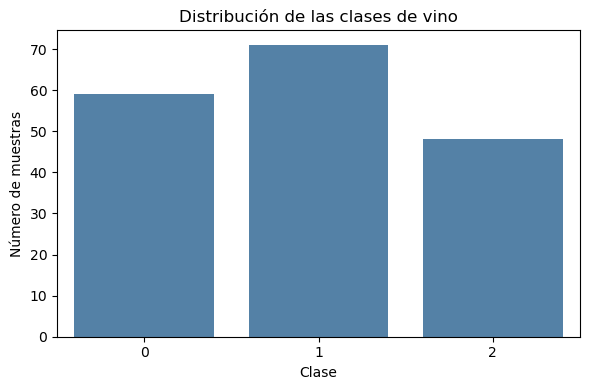

In [6]:
print("Cantidad por clase:")
print(df["target"].value_counts().sort_index())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target", order=[0, 1, 2], color="steelblue")
plt.title("Distribución de las clases de vino")
plt.xlabel("Clase")
plt.ylabel("Número de muestras")
plt.tight_layout()
plt.show()

La variable objetivo `target` presenta una distribución relativamente equilibrada entre las tres clases, con 59, 71 y 48 observaciones, respectivamente. Aunque existen diferencias en el número de muestras, no se observa un desbalance severo entre las clases.

### 3.2 Histogramas de las variables predictoras

Se inspeccionan visualmente las características o variables predictoras para identificar diferencias de escala y forma de sus distribuciones.

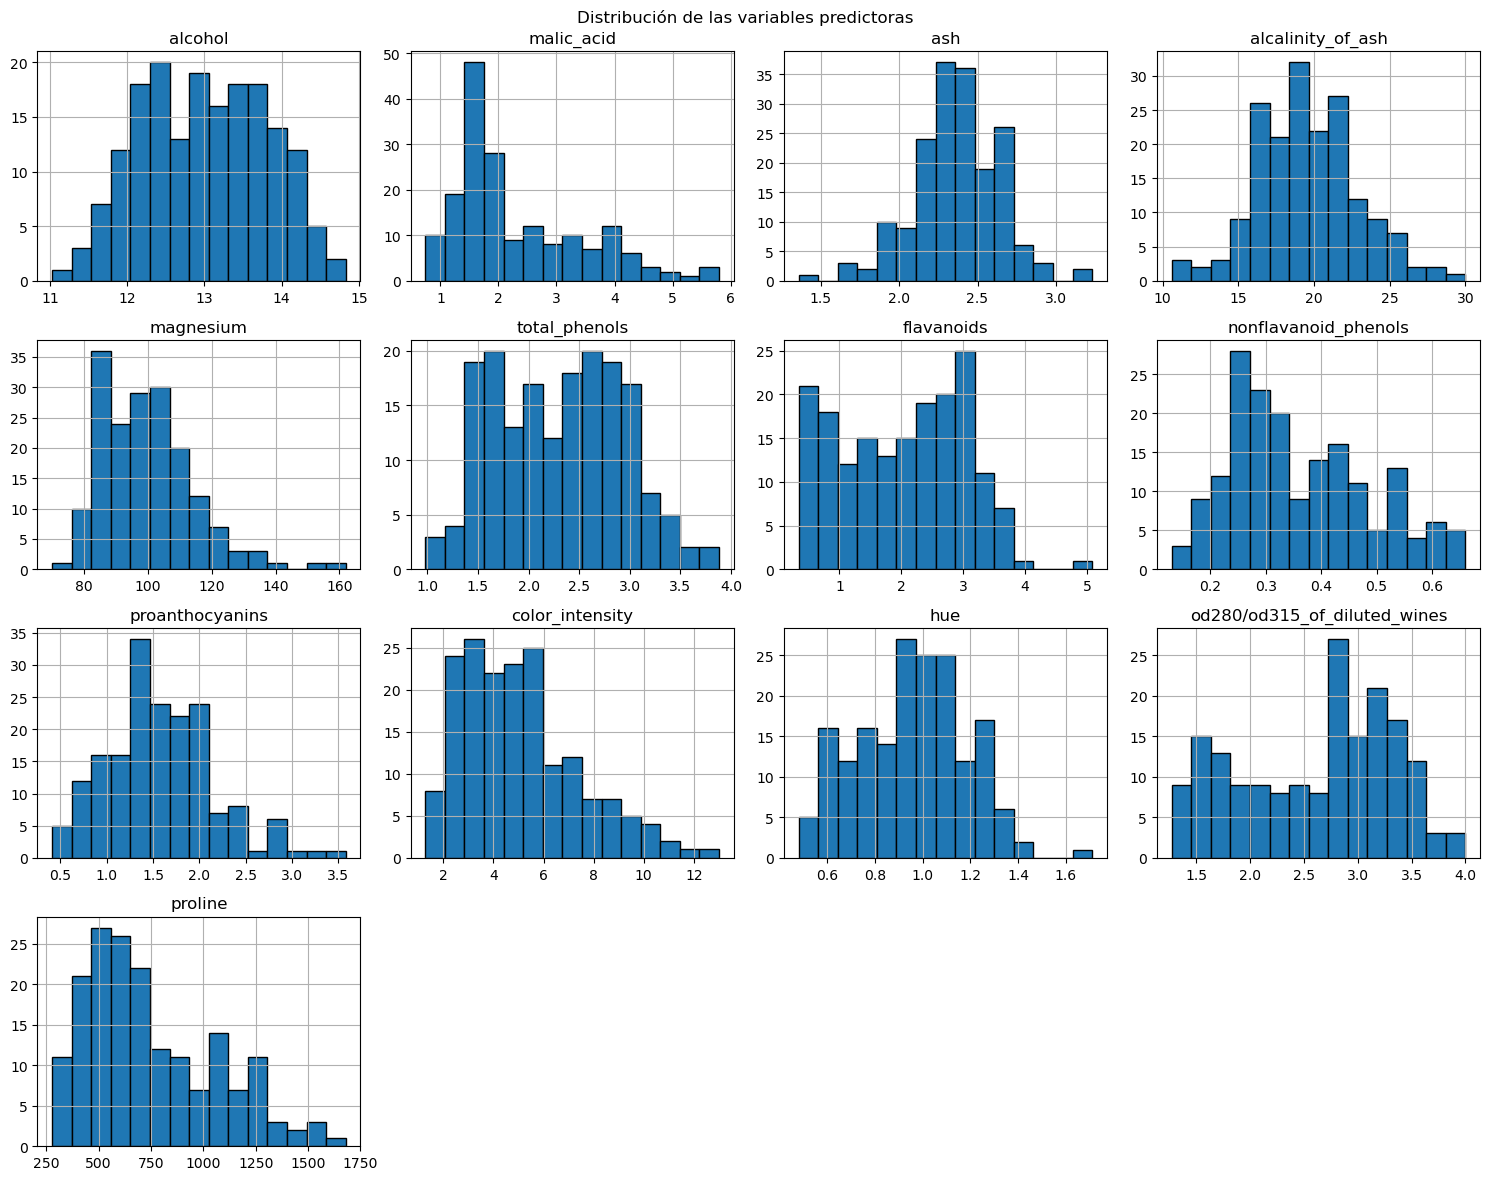

In [7]:
variables_predictoras = df.drop(columns=["target"]).columns

df[variables_predictoras].hist(figsize=(15, 12), bins=15, edgecolor="black")

plt.suptitle("Distribución de las variables predictoras")
plt.tight_layout()
plt.show()

### 3.3 Diagramas de cajas

Estos diagramas permiten observar la dispersión y detectar posibles valores atípicos. Un valor atípico no debe eliminarse automáticamente.

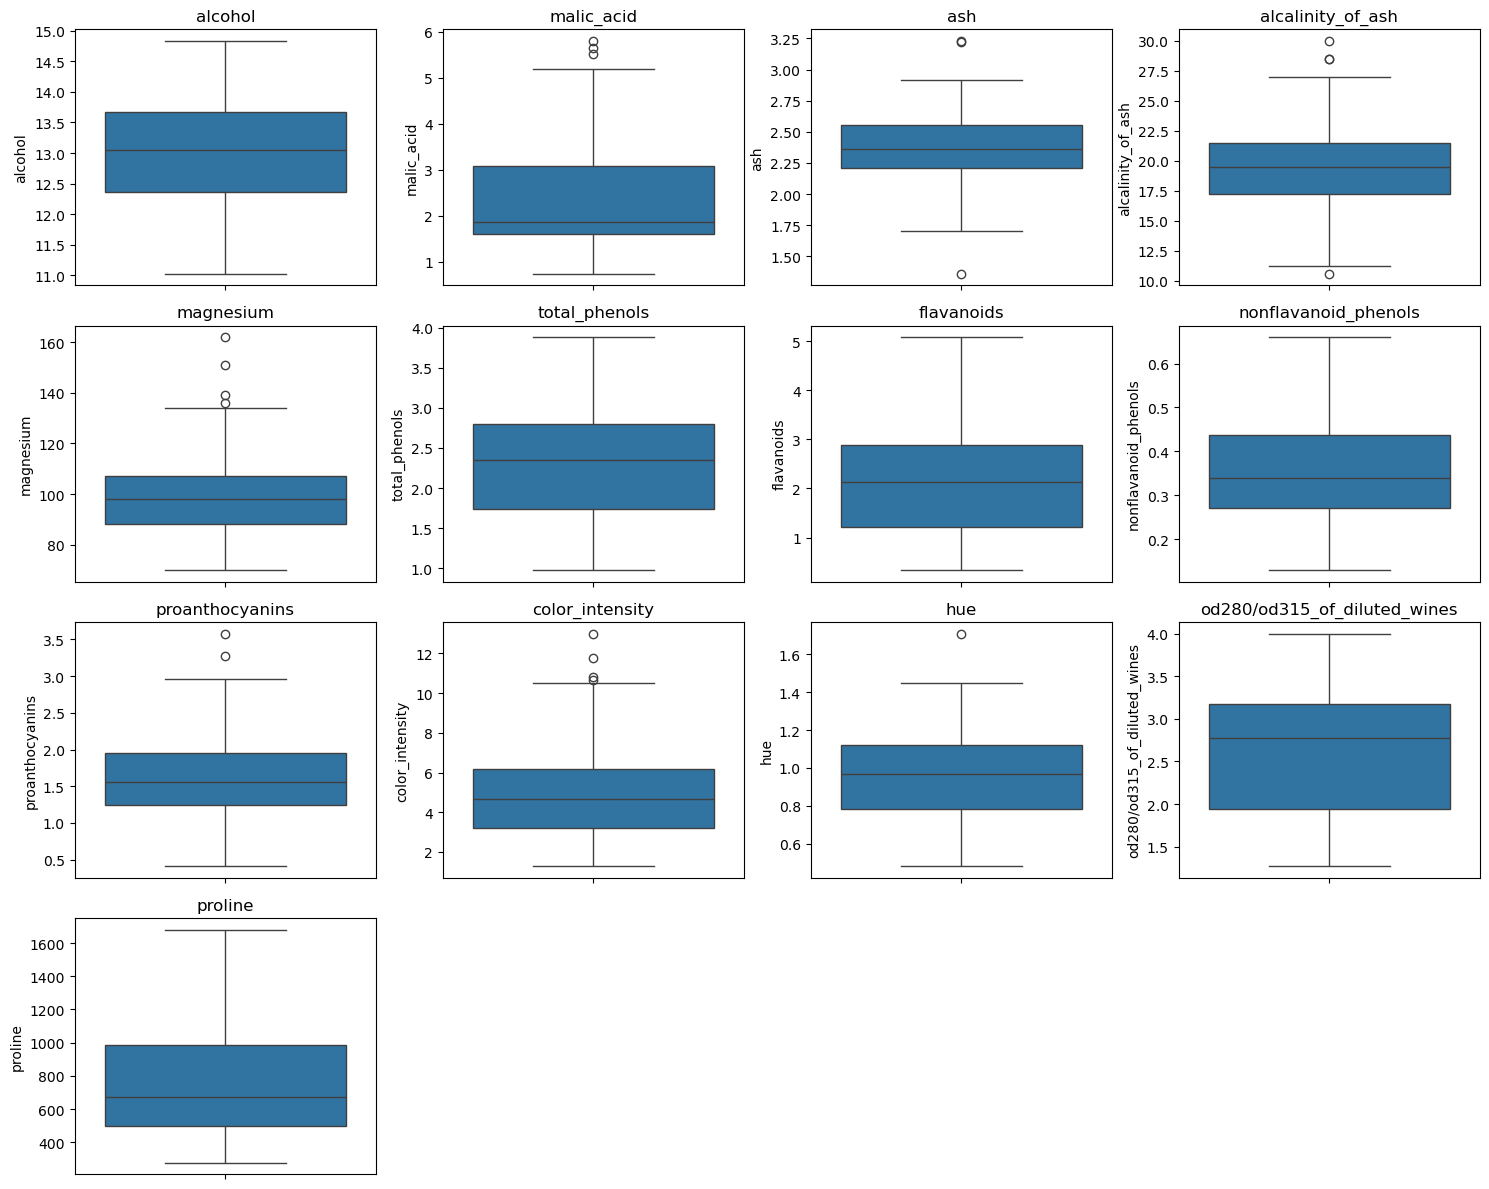

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(15, 12))
axes = axes.flatten()

for i, variable in enumerate(variables_predictoras):
    sns.boxplot(y=df[variable], ax=axes[i])
    axes[i].set_title(variable)

for j in range(len(variables_predictoras), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

Los histogramas muestran que las variables predictoras presentan distribuciones diferentes, algunas aproximadamente simétricas y otras con asimetrías, como `malic_acid`, `color_intensity` y `proline`. También se observan diferencias importantes en sus escalas y dispersión, lo que justifica utilizar estandarización antes de entrenar los modelos de regresión logística.

Los diagramas de cajas permiten identificar posibles valores atípicos en variables como `malic_acid`, `magnesium`, `color_intensity` y `proanthocyanins`. Sin embargo, estos valores no necesariamente representan errores y, por tanto, no se eliminarán sin evidencia adicional que justifique hacerlo.

### 3.4 Correlación entre variables predictoras

Se calcula la correlación de Pearson de las 13 variables numéricas. Una correlación alta no obliga a eliminar características, pero permite identificar posibles redundancias. `target` no se incluye en esta matriz porque sus etiquetas representan categorías.

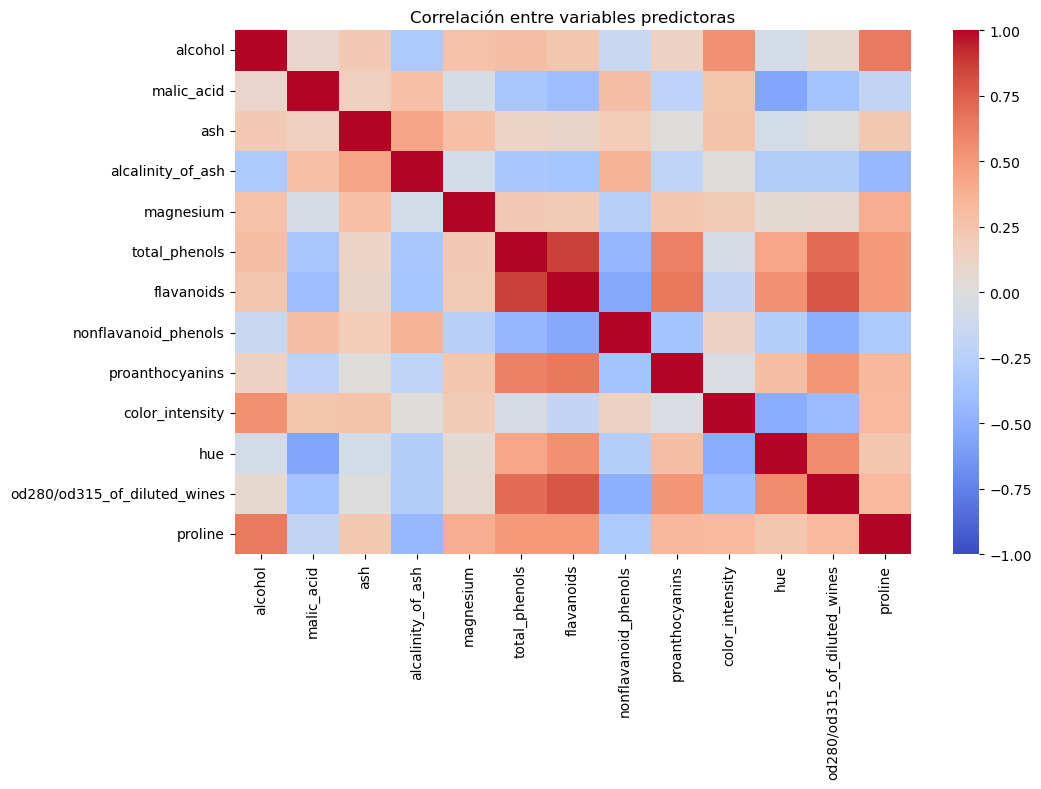

In [9]:
variables_predictoras = wine.feature_names
correlaciones = df[variables_predictoras].corr(method="pearson")

plt.figure(figsize=(11, 8))
sns.heatmap(correlaciones, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlación entre variables predictoras")
plt.tight_layout()
plt.show()

In [10]:
#instrucciones para imprimir en una tabla las 5 correlaciones más altas del dataset
mascara = np.triu(np.ones(correlaciones.shape), k=1).astype(bool)
correlaciones = correlaciones.where(mascara).stack().reset_index()
correlaciones.columns = ["Variable 1", "Variable 2", "Correlación"]
correlaciones["Correlación absoluta"] = correlaciones["Correlación"].abs()
top5 = correlaciones.sort_values(by="Correlación absoluta", ascending=False).head(5)
top5.round(3)

,Variable 1,Variable 2,Correlación,Correlación absoluta
50,total_phenols,flavanoids,0.865,0.865
61,flavanoids,od280/od315_of_diluted_wines,0.787,0.787
55,total_phenols,od280/od315_of_diluted_wines,0.700,0.700
58,flavanoids,proanthocyanins,0.653,0.653
11,alcohol,proline,0.644,0.644


El análisis de correlación de Pearson muestra que la relación más fuerte se presenta entre `total_phenols` y `flavanoids` (r = 0.865), seguida de `flavanoids` y `od280/od315_of_diluted_wines` (r = 0.787), y `total_phenols` y `od280/od315_of_diluted_wines` (r = 0.700). Estas correlaciones positivas indican que algunas características químicas tienden a variar conjuntamente; pero no implica necesariamente que deban eliminarse.

En conclusión, se conservarán las 13 variables predictoras para el entrenamiento de los modelos.

## 4. Preparación de los datos

Se separan las características (`X`) y la clase (`y`). Se reserva el 20 % de las muestras para prueba. Se utiliza `stratify=y` para conservar aproximadamente la proporción de cada clase en ambos conjuntos. Después se estandarizan las variables predictoras. `StandardScaler` se ajusta solo con los datos de entrenamiento, para evitar fuga de información hacia el modelo.

In [11]:
X = df[variables_predictoras].copy()
y = df["target"].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Clases en entrenamiento:")
print(y_train.value_counts().sort_index())
print("Clases en prueba:")
print(y_test.value_counts().sort_index())

Entrenamiento: (142, 13)
Prueba: (36, 13)
Clases en entrenamiento:
target
0    47
1    57
2    38
Name: count, dtype: int64
Clases en prueba:
target
0    12
1    14
2    10
Name: count, dtype: int64


El hiperparámetro stratify de la función `train_test_split()` particiona el dataset de tal forma que se conserve en ambas particiones la misma distribución de los ejemplos por clase. 
Distribución original de los datos como se puede observar en las siguientes tablas:

| Clase | Total  | Original % |
|---|---:|---:|
| 0 | 59 | 33.15% |
| 1 | 71 | 39.89% |
| 2 | 48 | 26.97% |

Distribución de los ejemplos por clase en las particiones:

| Class | Training (142) | Training (%) | Test (36) | Test (%) |
|---|---:|---:|---:|---:|
| 0 | 47 | 33.10% | 12 | 33.33% |
| 1 | 57 | 40.14% | 14 | 38.89% |
| 2 | 38 | 26.76% | 10 | 27.78% |


In [12]:
scaler = StandardScaler()

X_train_preparado = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_preparado = pd.DataFrame(scaler.transform(X_test),columns=X_test.columns, index=X_test.index)

X_train_preparado.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
36,0.385801,-0.637871,1.776668,-1.224532,0.696430,0.526865,0.732292,-0.169549,-0.415783,-0.167467,0.624378,0.252908,0.467725
30,0.948519,-0.765445,1.253174,0.853284,0.091785,1.172795,1.333181,-0.590457,1.349742,0.305303,1.067155,0.151048,1.815768
26,0.523354,-0.519409,0.954034,-1.046433,-0.445678,0.930572,1.006382,-0.169549,-0.260002,-0.081509,-0.128343,0.893172,1.516203
12,0.973529,-0.555859,0.168793,-1.076116,-0.714409,0.526865,0.816627,-0.590457,0.363125,0.262324,0.890044,0.427526,1.932265
148,0.435820,0.820120,0.056615,0.556453,-0.512860,-0.555068,-1.291756,0.756449,-0.606183,1.474335,-1.766619,-1.435059,-0.297831


## 5. Modelos de Regresión

### 5.1 Regresión SoftMax sin regularización

Inicialmente entrenaremos un modelo de regresión logística utilizando las 13 variables predictoras del conjunto de datos Wine, sin aplicar regularización.
La regresión logística es un algoritmo de aprendizaje supervisado que permite resolver problemas de clasificación. Aunque su nombre incluye el término regresión, su objetivo es estimar probabilidades de pertenencia a diferentes clases y utilizarlas para realizar predicciones.
En este caso, el modelo debe clasificar cada muestra de vino en una de las tres clases disponibles, utilizando sus características químicas.
Este primer modelo servirá como referencia para comparar posteriormente los efectos de la regularización L2 y L1 sobre los coeficientes y el rendimiento de clasificación.

In [13]:
modelo_sin_reg = LogisticRegression(C=np.inf, solver="newton-cg", max_iter=1000)
modelo_sin_reg.fit(X_train_preparado, y_train)

LogisticRegression(C=inf, max_iter=1000, solver='newton-cg')

In [14]:
def evaluar_modelo(nombre_modelo, tipo_evaluacion, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)
    
    print(f"Modelo: {nombre_modelo}")
    print(f"Accuracy : {accuracy:.4f}")
   
    print(f"\nReporte de clasificación para: - {tipo_evaluacion}")
    reporte = classification_report(y_true, y_pred, digits=4, output_dict=True)
    print(classification_report(y_true, y_pred, digits=4))

    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, cmap="Blues")
    plt.title(f"Matriz de confusión - {nombre_modelo}")
    plt.show()
    return {
        "Modelo": nombre_modelo,
        "Accuracy": accuracy,
        "Precision": reporte["macro avg"]["precision"],
        "Recall": reporte["macro avg"]["recall"],
        "F1-score": reporte["macro avg"]["f1-score"]
    }

Modelo: SoftMax Regression
Accuracy : 1.0000

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        47
           1     1.0000    1.0000    1.0000        57
           2     1.0000    1.0000    1.0000        38

    accuracy                         1.0000       142
   macro avg     1.0000    1.0000    1.0000       142
weighted avg     1.0000    1.0000    1.0000       142



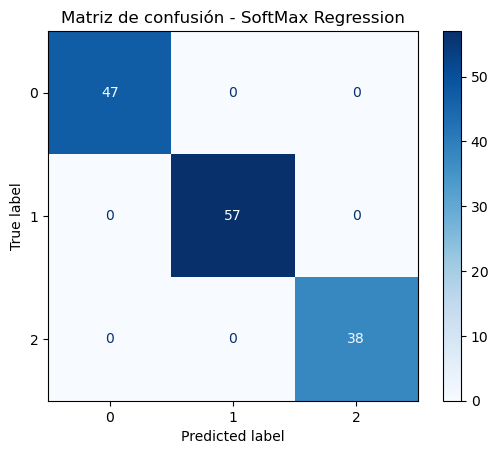

Modelo: SoftMax Regression
Accuracy : 0.9722

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     0.9333    1.0000    0.9655        14
           2     1.0000    0.9000    0.9474        10

    accuracy                         0.9722        36
   macro avg     0.9778    0.9667    0.9710        36
weighted avg     0.9741    0.9722    0.9720        36



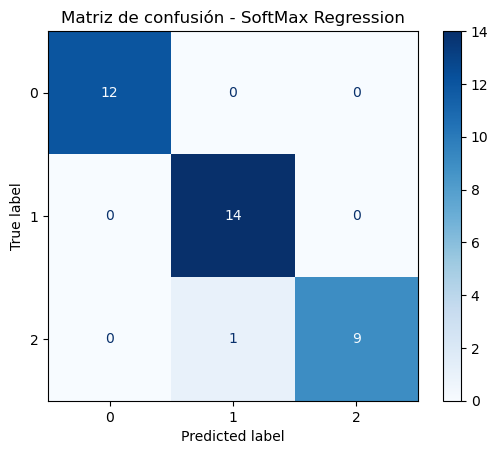

In [15]:
logistic_pred_train = modelo_sin_reg.predict(X_train_preparado)
logistic_pred_test = modelo_sin_reg.predict(X_test_preparado)

logistic_train_metrics = evaluar_modelo('SoftMax Regression', 'Training',  y_train, logistic_pred_train)
logistic_test_metrics = evaluar_modelo('SoftMax Regression', 'Testing', y_test, logistic_pred_test)


El modelo de regresión SoftMax sin regularización obtuvo un accuracy del 100% en entrenamiento y del 97.22% en prueba, lo que indica un excelente desempeño en la clasificación de las tres clases de vinos. En el conjunto de prueba, el modelo clasificó correctamente 35 de las 36 muestras. Las métricas de precisión, recall y F1-score macro presentan valores superiores al 96%, lo que evidencia un buen desempeño en las tres clases. Sin embargo, el rendimiento perfecto en entrenamiento y la ligera disminución en prueba podrían sugerir cierto grado de sobreajuste, aunque los resultados no proporcionan evidencia suficiente para concluir que existe un problema importante de generalización.

### 5.2 Regresión SoftMax con regularización L2

`LogisticRegression` usa por defecto regularización L2. El parámetro `C` controla la fuerza de la regularización: valores menores de `C` implican mayor regularización.

In [16]:
ridge_model = LogisticRegression(C=1.0, solver="newton-cg", max_iter=5000)
ridge_model.fit(X_train_preparado, y_train)

LogisticRegression(max_iter=5000, solver='newton-cg')

Modelo: Ridge Regression
Accuracy : 1.0000

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        47
           1     1.0000    1.0000    1.0000        57
           2     1.0000    1.0000    1.0000        38

    accuracy                         1.0000       142
   macro avg     1.0000    1.0000    1.0000       142
weighted avg     1.0000    1.0000    1.0000       142



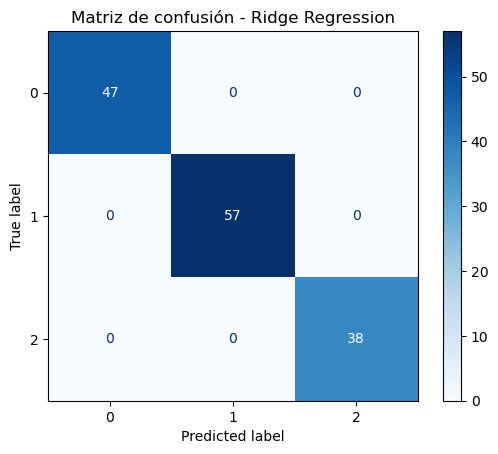

Modelo: Ridge Regression
Accuracy : 0.9722

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     0.9333    1.0000    0.9655        14
           2     1.0000    0.9000    0.9474        10

    accuracy                         0.9722        36
   macro avg     0.9778    0.9667    0.9710        36
weighted avg     0.9741    0.9722    0.9720        36



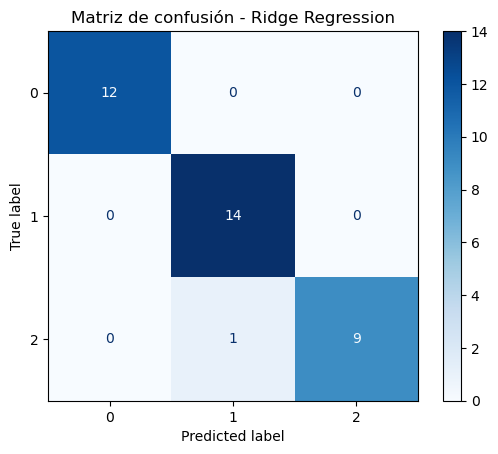

In [17]:
ridge_pred_train = ridge_model.predict(X_train_preparado)
ridge_pred_test = ridge_model.predict(X_test_preparado)

ridge_train_metrics = evaluar_modelo('Ridge Regression', 'Training',  y_train, ridge_pred_train)
ridge_test_metrics = evaluar_modelo('Ridge Regression', 'Testing', y_test, ridge_pred_test)


Estos resultados son muy parecidos a los obtenidos por el modelo sin regularización, por lo que la incorporación de L2, con C = 1.0, no produjo mejoras en las métricas de clasificación. Aunque la regularización L2 busca controlar la magnitud de los coeficientes y reducir el riesgo de sobreajuste, los resultados obtenidos no permiten afirmar que haya mejorado la capacidad de generalización del modelo. 

### 5.3 Regresión SoftMax con regularización L1 (tipo Lasso)

La regularización L1 penaliza la suma de los valores absolutos de los coeficientes. A diferencia de L2, puede llevar algunos coeficientes exactamente a cero. Este comportamiento puede servir como selección implícita de características.

Aunque aquí hablamos de una penalización de tipo Lasso, el modelo sigue siendo de clasificación logística; no se utiliza la clase `Lasso` de Scikit-learn, que está diseñada para regresión de una variable continua.

Se emplea `solver="saga"`, que permite regularización L1 para clasificación multiclase.

In [18]:
lasso_model = LogisticRegression(penalty="l1", solver="saga", C=0.1, max_iter=10000, random_state=42)
lasso_model.fit(X_train_preparado, y_train)

LogisticRegression(C=0.1, max_iter=10000, penalty='l1', random_state=42,
                   solver='saga')

Modelo: Lasso Regression
Accuracy : 0.9718

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     0.9783    0.9574    0.9677        47
           1     0.9649    0.9649    0.9649        57
           2     0.9744    1.0000    0.9870        38

    accuracy                         0.9718       142
   macro avg     0.9725    0.9741    0.9732       142
weighted avg     0.9719    0.9718    0.9718       142



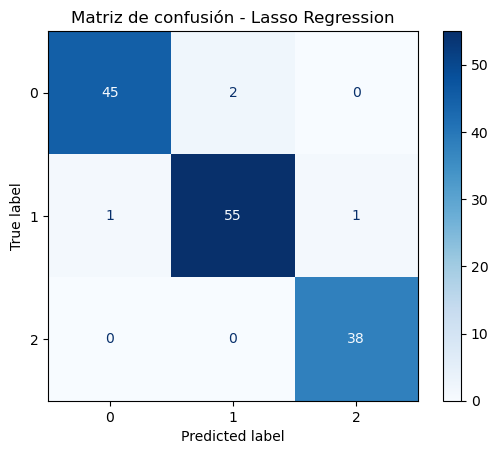

Modelo: Lasso Regression
Accuracy : 1.0000

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     1.0000    1.0000    1.0000        14
           2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



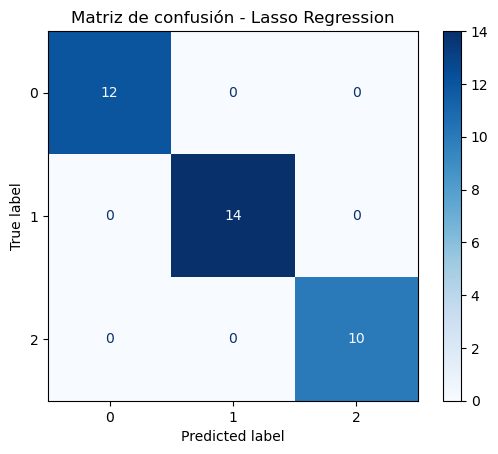

In [19]:
lasso_pred_train = lasso_model.predict(X_train_preparado)
lasso_pred_test = lasso_model.predict(X_test_preparado)

lasso_train_metrics = evaluar_modelo('Lasso Regression', 'Training',  y_train, lasso_pred_train)
lasso_test_metrics = evaluar_modelo('Lasso Regression', 'Testing', y_test, lasso_pred_test)

El modelo de regresión SoftMax con regularización L1 (C = 0.1) obtuvo un accuracy del 97.18% en entrenamiento y del 100% en prueba, clasificando correctamente las 36 muestras del conjunto de prueba. Las métricas de precisión, recall y F1-score macro también alcanzaron valores de 1.0 en prueba, lo que indica un desempeño perfecto en esta partición de los datos. Sin embargo, se deben realizar evaluaciones adiconales antes de concluir que SoftMax con L1 tuvo un mejor desemeplo que los otros modelos de regresión dado que el conjunto de prueba contiene únicamente 36 observaciones, lo que corresponde a una sola muestra clasificada correctamente. 

### 5.4. Diseño experimental: exploración de hiperparámetros con GridSearchCV para regresión

#### 5.4.1 Ajuste de hiperparámetros para LogisticRegression sin regularización

In [20]:
#Regresión SoftMax sin termino de regularización
SoftMax_model = LogisticRegression(C=np.inf, solver="newton-cg", max_iter=2000)

param_grid = {"tol": [1e-3, 1e-4, 1e-5]}

grid_SoftMax = GridSearchCV(SoftMax_model, param_grid, scoring="accuracy", cv=5)
grid_SoftMax.fit(X_train_preparado, y_train)

GridSearchCV(cv=5,
             estimator=LogisticRegression(C=inf, max_iter=2000,
                                          solver='newton-cg'),
             param_grid={'tol': [0.001, 0.0001, 1e-05]}, scoring='accuracy')

In [21]:
resultados_grid_SoftMax = pd.DataFrame(grid_SoftMax.cv_results_)
display(resultados_grid_SoftMax[["param_tol", "mean_test_score", "std_test_score"]].round(4))

,param_tol,mean_test_score,std_test_score
0,0.0010,0.986,0.0172
1,0.0001,0.986,0.0172
2,0.0000,0.986,0.0172


In [22]:
print("Mejor parámetro:", grid_SoftMax.best_params_)
grid_SoftMax_model = grid_SoftMax.best_estimator_
print(f"Accuracy promedio en validación: {grid_SoftMax.best_score_:.4f}")

Mejor parámetro: {'tol': 0.001}
Accuracy promedio en validación: 0.9860


Modelo: grid_SoftMax Regression
Accuracy : 1.0000

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        47
           1     1.0000    1.0000    1.0000        57
           2     1.0000    1.0000    1.0000        38

    accuracy                         1.0000       142
   macro avg     1.0000    1.0000    1.0000       142
weighted avg     1.0000    1.0000    1.0000       142



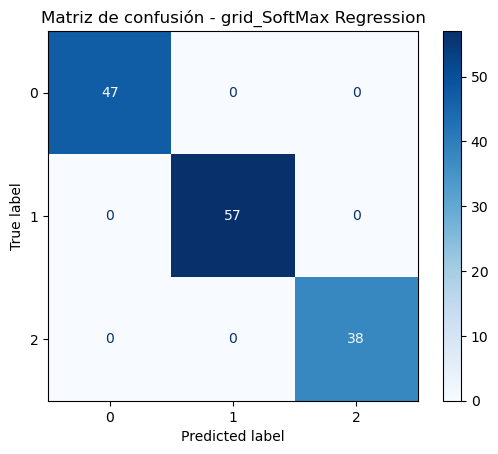

Modelo: grid_SoftMax Regression
Accuracy : 0.9722

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     0.9333    1.0000    0.9655        14
           2     1.0000    0.9000    0.9474        10

    accuracy                         0.9722        36
   macro avg     0.9778    0.9667    0.9710        36
weighted avg     0.9741    0.9722    0.9720        36



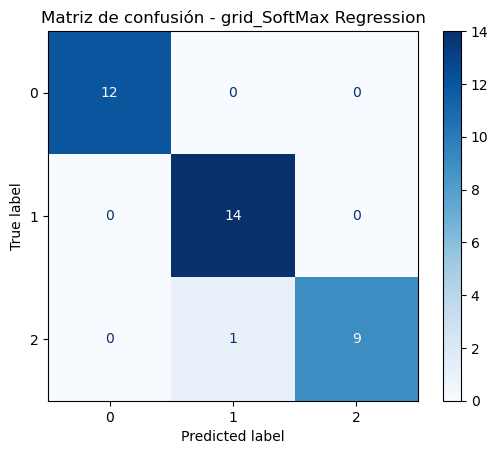

In [23]:
grid_SoftMax_pred_train = grid_SoftMax_model.predict(X_train_preparado)
grid_SoftMax_pred_test = grid_SoftMax_model.predict(X_test_preparado)

grid_SoftMax_train_metrics = evaluar_modelo('grid_SoftMax Regression', 'Training',  y_train, grid_SoftMax_pred_train)
grid_SoftMax_test_metrics = evaluar_modelo('grid_SoftMax Regression', 'Testing', y_test, grid_SoftMax_pred_test)

La búsqueda de hiperparámetros mediante GridSearchCV, utilizando validación cruzada de 5 particiones, permitió evaluar tres valores del parámetro de tolerancia (tol): 0.001, 0.0001 y 0.00001. Los tres valores produjeron el mismo accuracy promedio de 98.60% en validación cruzada, con una desviación estándar de 0.0172. Esto indica que, para los valores evaluados, la modificación de la tolerancia no produjo diferencias en el rendimiento del modelo. GridSearchCV seleccionó tol = 0.001 como mejor configuración. Sin embargo, esta selección se debe a que todos los valores alcanzaron el mismo desempeño y GridSearchCV conserva la primera configuración en caso de empate.

#### 5.4.2 Ajuste de hiperparámetros para LogisticRegression con regularización

Tanto Ridge (con L2) y Lasso con (con L1) se implementan con la función LogisticRegressión, la librería distingue que método aplicar con el hiperparámetro `penalty` por lo tanto la selección de estas dos opciones de regresión con restricción se integra en este ejemplo a lista de hiperparámetros que se envía a la función `GridSearchCV`.

In [24]:
modelo = LogisticRegression(solver="saga", max_iter=5000, random_state=42)

param_grid = {"penalty": ["l1", "l2"], "C": [0.01, 0.1, 1, 10, 100]}

grid_reg = GridSearchCV(modelo, param_grid, scoring="accuracy", cv=5)
grid_reg.fit(X_train_preparado, y_train)

GridSearchCV(cv=5,
             estimator=LogisticRegression(max_iter=5000, random_state=42,
                                          solver='saga'),
             param_grid={'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l1', 'l2']},
             scoring='accuracy')

In [25]:
resultados_grid_reg = pd.DataFrame(grid_reg.cv_results_)
resultados_grid_reg = pd.DataFrame(grid_reg.cv_results_).rename(columns={"mean_test_score": "mean_val_score", 
                                                                         "std_test_score": "std_val_score"})
display(resultados_grid_reg[["param_penalty", "param_C", "mean_val_score", "std_val_score"]].round(4))

,param_penalty,param_C,mean_val_score,std_val_score
0,l1,0.01,0.4012,0.0103
1,l2,0.01,0.9862,0.0276
2,l1,0.10,0.9579,0.0405
3,l2,0.10,0.9862,0.0276
4,l1,1.00,0.9862,0.0276
5,l2,1.00,0.9860,0.0172
6,l1,10.00,0.9860,0.0172
7,l2,10.00,0.9860,0.0172
8,l1,100.00,0.9860,0.0172
9,l2,100.00,0.9860,0.0172


In [26]:
print("Mejor parámetro:", grid_reg.best_params_)
grid_reg_model = grid_reg.best_estimator_
print(f"Accuracy promedio en validación: {grid_reg.best_score_:.4f}")

Mejor parámetro: {'C': 0.01, 'penalty': 'l2'}
Accuracy promedio en validación: 0.9862


Modelo: SoftMax con regularización
Accuracy : 0.9859

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     0.9792    1.0000    0.9895        47
           1     1.0000    0.9649    0.9821        57
           2     0.9744    1.0000    0.9870        38

    accuracy                         0.9859       142
   macro avg     0.9845    0.9883    0.9862       142
weighted avg     0.9862    0.9859    0.9859       142



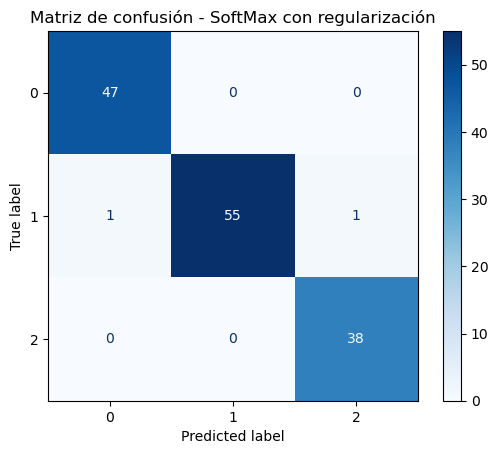

Modelo: SoftMax con regularización
Accuracy : 1.0000

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     1.0000    1.0000    1.0000        14
           2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



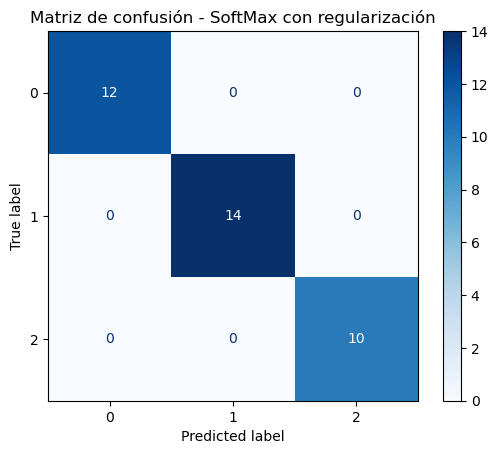

In [27]:
grid_reg_pred_train = grid_reg_model.predict(X_train_preparado)
grid_reg_pred_test = grid_reg_model.predict(X_test_preparado)

grid_reg_train_metrics = evaluar_modelo('SoftMax con regularización', 'Training',  y_train, grid_reg_pred_train)
grid_reg_test_metrics = evaluar_modelo('SoftMax con regularización', 'Testing', y_test, grid_reg_pred_test)

In [28]:
modelo = LogisticRegression(solver="saga", max_iter=5000, random_state=42)
param_grid2 = {"penalty": ["l1", "l2"], "C": [0.05, 0.5, 5, 15, 105]}

grid_reg2 = GridSearchCV(modelo, param_grid2, scoring="accuracy", cv=5)
grid_reg2.fit(X_train_preparado, y_train)

GridSearchCV(cv=5,
             estimator=LogisticRegression(max_iter=5000, random_state=42,
                                          solver='saga'),
             param_grid={'C': [0.05, 0.5, 5, 15, 105], 'penalty': ['l1', 'l2']},
             scoring='accuracy')

In [29]:
print("Mejor parámetro:", grid_reg2.best_params_)
grid_reg2_model = grid_reg2.best_estimator_
print(f"Accuracy promedio en validación: {grid_reg2.best_score_:.4f}")

Mejor parámetro: {'C': 0.5, 'penalty': 'l2'}
Accuracy promedio en validación: 0.9931


Modelo: SoftMax con regularización 2
Accuracy : 1.0000

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        47
           1     1.0000    1.0000    1.0000        57
           2     1.0000    1.0000    1.0000        38

    accuracy                         1.0000       142
   macro avg     1.0000    1.0000    1.0000       142
weighted avg     1.0000    1.0000    1.0000       142



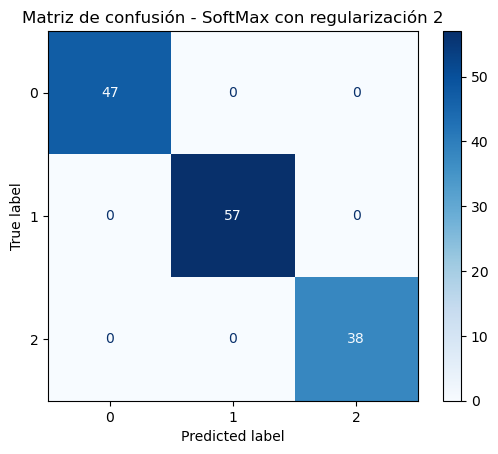

Modelo: SoftMax con regularización 2
Accuracy : 0.9722

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     0.9333    1.0000    0.9655        14
           2     1.0000    0.9000    0.9474        10

    accuracy                         0.9722        36
   macro avg     0.9778    0.9667    0.9710        36
weighted avg     0.9741    0.9722    0.9720        36



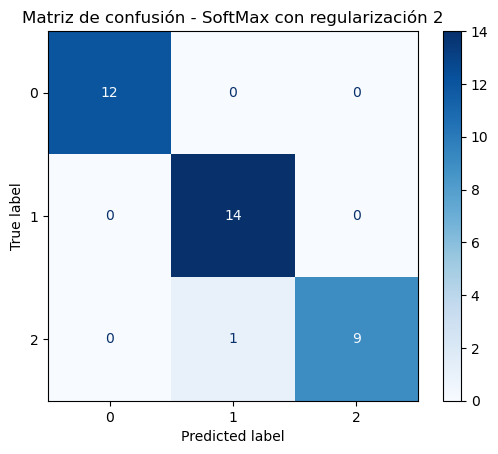

In [30]:
grid_reg2_pred_train = grid_reg2_model.predict(X_train_preparado)
grid_reg2_pred_test = grid_reg2_model.predict(X_test_preparado)

grid_reg2_train_metrics = evaluar_modelo('SoftMax con regularización 2', 'Training', y_train, grid_reg2_pred_train)
grid_reg2_test_metrics = evaluar_modelo('SoftMax con regularización 2', 'Testing', y_test, grid_reg2_pred_test)

In [31]:
resultados_grid_reg2 = pd.DataFrame(grid_reg2.cv_results_)
resultados_grid_reg2 = pd.DataFrame(grid_reg2.cv_results_).rename(columns={"mean_test_score": "mean_val_score", 
                                                                         "std_test_score": "std_val_score"})
display(resultados_grid_reg2[["param_penalty", "param_C", "mean_val_score", "std_val_score"]].round(4))

,param_penalty,param_C,mean_val_score,std_val_score
0,l1,0.05,0.9369,0.0633
1,l2,0.05,0.9862,0.0276
2,l1,0.50,0.9862,0.0276
3,l2,0.50,0.9931,0.0138
4,l1,5.00,0.9860,0.0172
5,l2,5.00,0.9860,0.0172
6,l1,15.00,0.9860,0.0172
7,l2,15.00,0.9860,0.0172
8,l1,105.00,0.9860,0.0172
9,l2,105.00,0.9860,0.0172


En la primera búsqueda de hiperparámetros, GridSearchCV seleccionó la regularización L2 con C = 0.01, alcanzando un accuracy promedio de 98.62% en validación cruzada. El modelo optimizado obtuvo un accuracy de 98.59% en entrenamiento y de 100% en prueba, clasificando correctamente las 36 muestras de este último conjunto. En la segunda búsqueda, al modificar los valores de C, la mejor configuración fue nuevamente L2, pero con C = 0.5, alcanzando un accuracy promedio de 99.31% en validación cruzada. Sin embargo, este modelo obtuvo un accuracy del 100% en entrenamiento y del 97.22% en prueba.

## 6. Modelos basados en árboles de decisión

### 6.1 Árboles de decisión

In [32]:
modelo_tree = DecisionTreeClassifier(random_state=42)
modelo_tree.fit(X_train_preparado, y_train)

DecisionTreeClassifier(random_state=42)

Modelo: Decision Tree
Accuracy : 1.0000

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        47
           1     1.0000    1.0000    1.0000        57
           2     1.0000    1.0000    1.0000        38

    accuracy                         1.0000       142
   macro avg     1.0000    1.0000    1.0000       142
weighted avg     1.0000    1.0000    1.0000       142



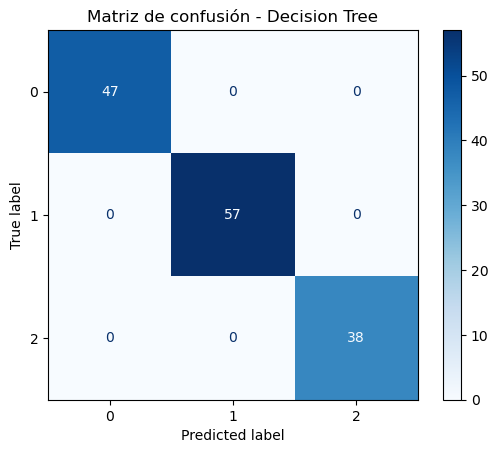

Modelo: Decision Tree
Accuracy : 0.9444

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     1.0000    0.9167    0.9565        12
           1     0.8750    1.0000    0.9333        14
           2     1.0000    0.9000    0.9474        10

    accuracy                         0.9444        36
   macro avg     0.9583    0.9389    0.9457        36
weighted avg     0.9514    0.9444    0.9450        36



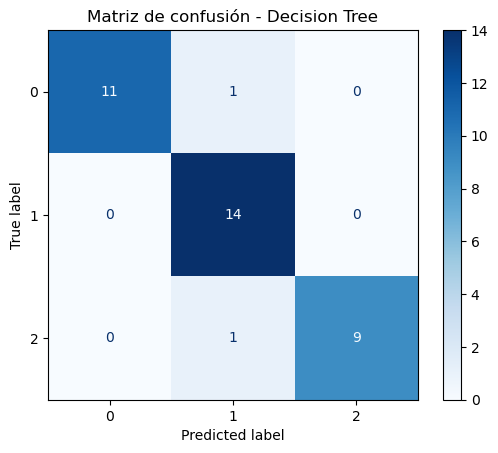

In [33]:
tree_pred_train = modelo_tree.predict(X_train_preparado)
tree_pred_test = modelo_tree.predict(X_test_preparado)

tree_train_metrics = evaluar_modelo('Decision Tree', 'Training', y_train, tree_pred_train)
tree_test_metrics = evaluar_modelo('Decision Tree', 'Testing', y_test, tree_pred_test)

In [34]:
print("Profundidad:", modelo_tree.get_depth())
print("Número de hojas:", modelo_tree.get_n_leaves())

Profundidad: 4
Número de hojas: 8


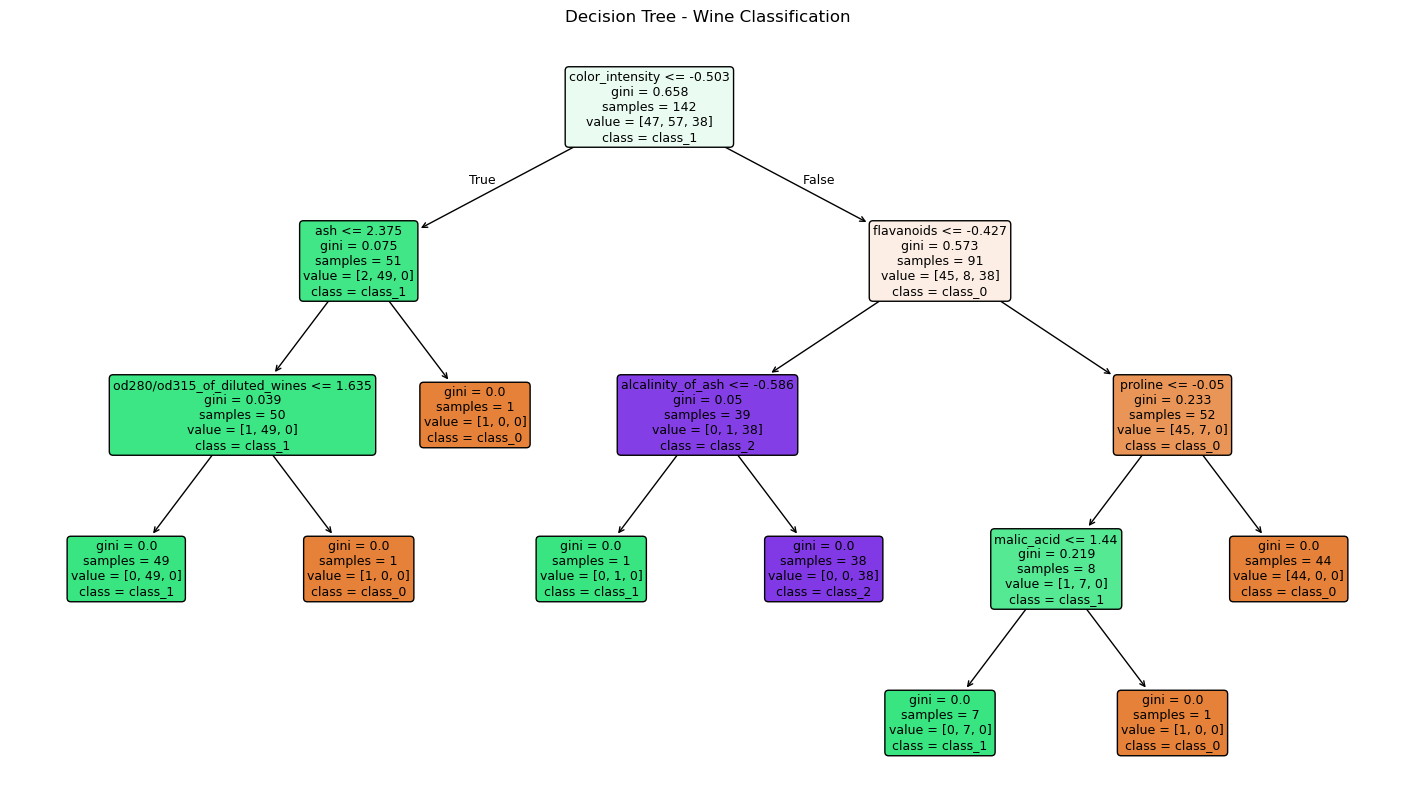

In [35]:
plt.figure(figsize=(18, 10))
plot_tree(modelo_tree, feature_names=X_train.columns, class_names=wine.target_names, 
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree - Wine Classification")
plt.show()

El modelo de árbol de decisión obtuvo un accuracy del 100% en entrenamiento y del 94.44% en prueba, clasificando correctamente 34 de las 36 muestras del conjunto de prueba. El F1-score macro alcanzó un valor de 0.9457, lo que indica un buen desempeño en las tres clases. La diferencia entre los resultados de entrenamiento y prueba sugiere cierto grado de sobreajuste. Sin embargo, dado el tamaño reducido del conjunto de prueba, no es posible afirmar que exista un problema importante de generalización.

### 6.2 Random Forest

In [36]:
modelo_rf = RandomForestClassifier(random_state=42)
modelo_rf.fit(X_train_preparado, y_train)

RandomForestClassifier(random_state=42)

Modelo: Random Forest
Accuracy : 1.0000

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        47
           1     1.0000    1.0000    1.0000        57
           2     1.0000    1.0000    1.0000        38

    accuracy                         1.0000       142
   macro avg     1.0000    1.0000    1.0000       142
weighted avg     1.0000    1.0000    1.0000       142



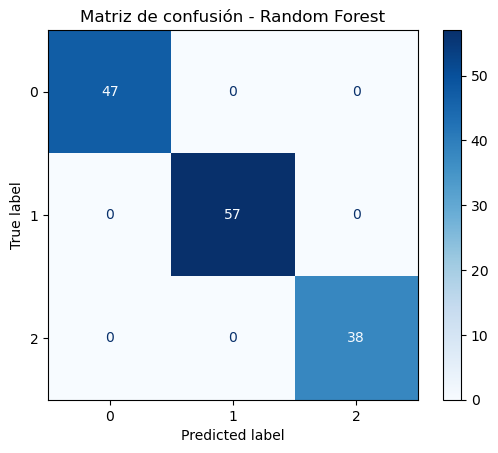

Modelo: Random Forest
Accuracy : 1.0000

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     1.0000    1.0000    1.0000        14
           2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



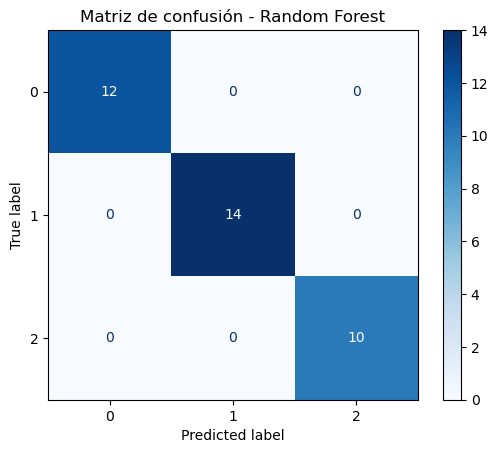

In [37]:
rf_pred_train = modelo_rf.predict(X_train_preparado)
rf_pred_test = modelo_rf.predict(X_test_preparado)

rf_train_metrics = evaluar_modelo('Random Forest', 'Training', y_train, rf_pred_train)
rf_test_metrics = evaluar_modelo('Random Forest', 'Testing', y_test, rf_pred_test)

El modelo Random Forest obtuvo un accuracy del 100% tanto en entrenamiento como en prueba, clasificando correctamente las 36 muestras del conjunto de prueba. Las métricas de precisión, recall y F1-score también alcanzaron valores de 1.0 para las tres clases, lo que evidencia un excelente desempeño de clasificación. En comparación con el árbol de decisión base, que obtuvo un accuracy del 94.44% en prueba, Random Forest presentó un mejor rendimiento, clasificando correctamente las dos muestras que el árbol individual había clasificado incorrectamente.

### 6.3 Ajuste de hiperparámetros para los métodos basados en árboles

#### 6.3.1 Ajuste de hiperparámetros para árboles de decisión

In [38]:
param_grid_tree = {"criterion": ["gini", "entropy"],
                   "max_depth": [3, 5, 7, 10, None],
                   "min_samples_split": [2, 5, 10],
                   "min_samples_leaf": [1, 2, 4]}

In [39]:
grid_tree = GridSearchCV(modelo_tree, param_grid_tree, scoring="accuracy", cv=5, n_jobs=-1)
grid_tree.fit(X_train_preparado, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 10, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [40]:
resultados_grid_tree = pd.DataFrame(grid_tree.cv_results_)

resultados_grid_tree = resultados_grid_tree.rename(columns={"mean_test_score": "mean_val_score",
                                                            "std_test_score": "std_val_score"})

display(resultados_grid_tree.sort_values(by="mean_val_score", ascending=False).head(10)[["param_criterion", 
                                                                                         "param_max_depth", 
                                                                                         "param_min_samples_split",
                                                                                         "param_min_samples_leaf", 
                                                                                         "mean_val_score", 
                                                                                         "std_val_score"]].round(4))

,param_criterion,param_max_depth,param_min_samples_split,param_min_samples_leaf,mean_val_score,std_val_score
4,gini,3,5,2,0.9303,0.0486
3,gini,3,2,2,0.9303,0.0486
21,gini,7,2,2,0.9234,0.0549
22,gini,7,5,2,0.9234,0.0549
12,gini,5,2,2,0.9234,0.0549
13,gini,5,5,2,0.9234,0.0549
40,gini,None,5,2,0.9234,0.0549
39,gini,None,2,2,0.9234,0.0549
30,gini,10,2,2,0.9234,0.0549
31,gini,10,5,2,0.9234,0.0549


In [41]:
print("Mejores hiperparámetros:", grid_tree.best_params_)
print("Mejor accuracy promedio en validación:", round(grid_tree.best_score_, 4))

modelo_tree_optimizado = grid_tree.best_estimator_

Mejores hiperparámetros: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2}
Mejor accuracy promedio en validación: 0.9303


Modelo: Decision Tree GridSearch
Accuracy : 0.9859

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     1.0000    0.9787    0.9892        47
           1     0.9661    1.0000    0.9828        57
           2     1.0000    0.9737    0.9867        38

    accuracy                         0.9859       142
   macro avg     0.9887    0.9841    0.9862       142
weighted avg     0.9864    0.9859    0.9860       142



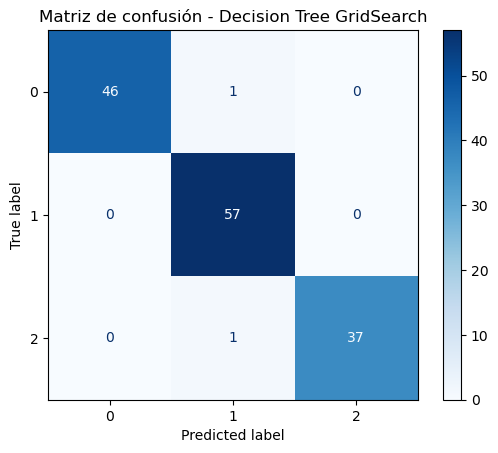

Modelo: Decision Tree GridSearch
Accuracy : 1.0000

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     1.0000    1.0000    1.0000        14
           2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



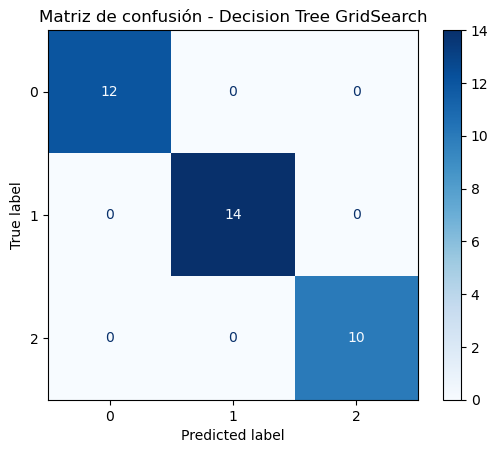

In [42]:
tree_pred_train = modelo_tree_optimizado.predict(X_train_preparado)
tree_pred_test = modelo_tree_optimizado.predict(X_test_preparado)

tree_train_metrics = evaluar_modelo('Decision Tree GridSearch', 'Training', y_train, tree_pred_train)
tree_test_metrics = evaluar_modelo('Decision Tree GridSearch', 'Testing', y_test, tree_pred_test)

In [43]:
print("Profundidad:", modelo_tree_optimizado.get_depth())
print("Número de hojas:", modelo_tree_optimizado.get_n_leaves())

Profundidad: 3
Número de hojas: 7


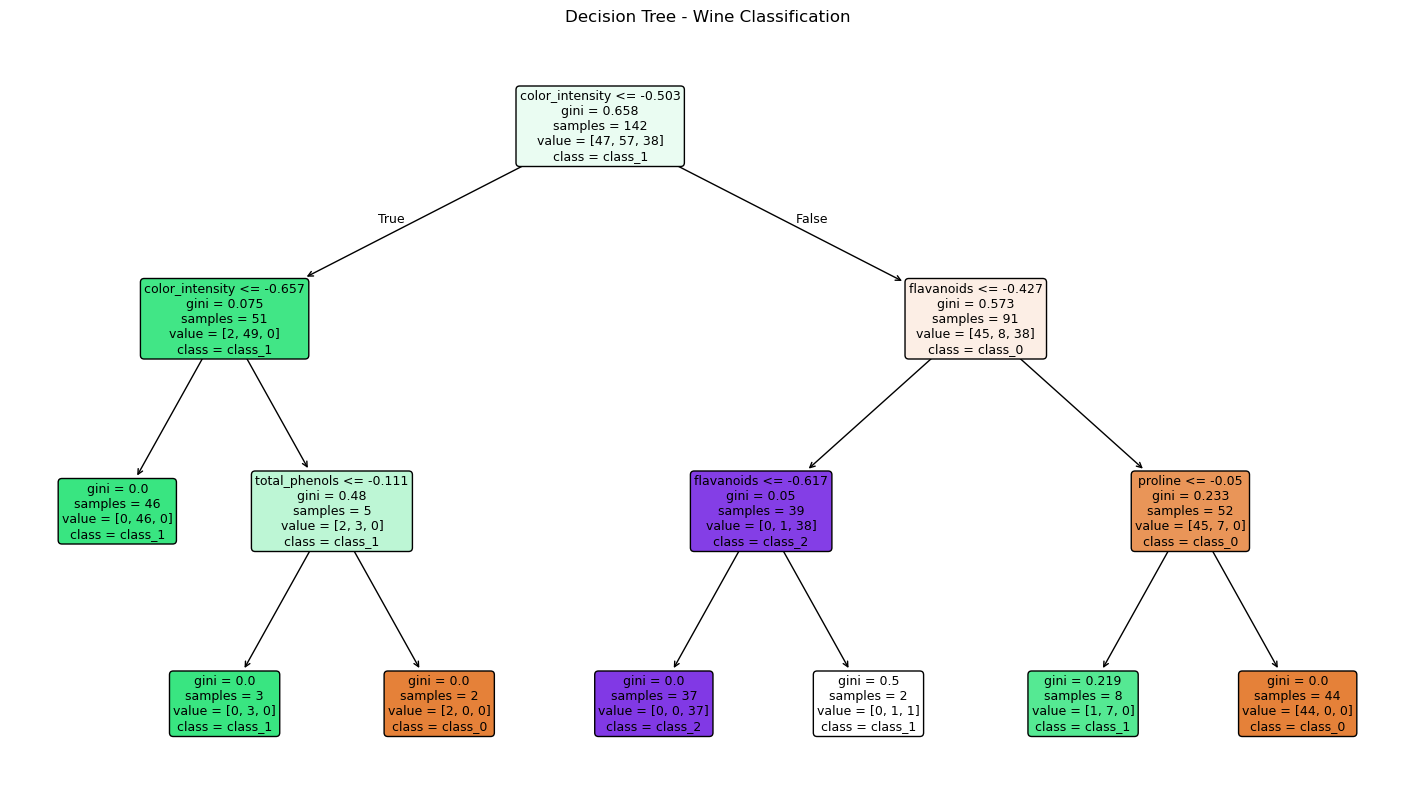

In [44]:
plt.figure(figsize=(18, 10))
plot_tree(modelo_tree_optimizado, feature_names=X_train.columns, class_names=wine.target_names, 
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree - Wine Classification")
plt.show()

El árbol de decisión optimizado obtiene mejores resultados en prueba, pero eso no demuestra que generalice mejor. De hecho, su accuracy promedio en validación cruzada es de 93.03%, considerablemente inferior al 100% obtenido en prueba.

#### 6.3.1 Ajuste de hiperparámetros para Random Forest con GridSeachCV

In [45]:
param_grid_rf = {"n_estimators": [50, 100, 200],
                 "max_depth": [3, 5, 10, None],
                 "min_samples_split": [2, 5],
                 "min_samples_leaf": [1, 2]}

In [46]:
modelo_rf = RandomForestClassifier(random_state=42)
grid_rf = GridSearchCV(modelo_rf, param_grid_rf, scoring="accuracy", cv=5, n_jobs=-1)
grid_rf.fit(X_train_preparado, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [3, 5, 10, None],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [50, 100, 200]},
             scoring='accuracy')

In [47]:
resultados_grid_rf = pd.DataFrame(grid_rf.cv_results_)

resultados_grid_rf = resultados_grid_rf.rename(columns={"mean_test_score": "mean_val_score",
                                                         "std_test_score": "std_val_score"})

display(resultados_grid_rf.sort_values(by="mean_val_score", ascending=False).head(10)[["param_n_estimators", 
                                                                                       "param_max_depth",
                                                                                       "param_min_samples_split", 
                                                                                       "param_min_samples_leaf",
                                                                                       "mean_val_score", 
                                                                                       "std_val_score"]].round(4))

,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,mean_val_score,std_val_score
0,50,3,2,1,0.9862,0.0276
1,100,3,2,1,0.9862,0.0276
3,50,3,5,1,0.9862,0.0276
4,100,3,5,1,0.9862,0.0276
6,50,3,2,2,0.9862,0.0276
5,200,3,5,1,0.9862,0.0276
7,100,3,2,2,0.9862,0.0276
8,200,3,2,2,0.9862,0.0276
12,50,5,2,1,0.9862,0.0276
9,50,3,5,2,0.9862,0.0276


In [48]:
print("Mejores hiperparámetros:", grid_rf.best_params_)
print("Mejor accuracy promedio en validación:", round(grid_rf.best_score_, 4))
modelo_rf_optimizado = grid_rf.best_estimator_

Mejores hiperparámetros: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}
Mejor accuracy promedio en validación: 0.9862


Modelo: Random Forest GridSearch
Accuracy : 1.0000

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        47
           1     1.0000    1.0000    1.0000        57
           2     1.0000    1.0000    1.0000        38

    accuracy                         1.0000       142
   macro avg     1.0000    1.0000    1.0000       142
weighted avg     1.0000    1.0000    1.0000       142



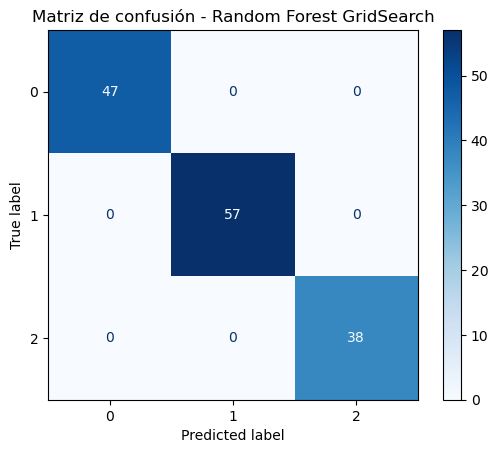

Modelo: Random Forest GridSearch
Accuracy : 1.0000

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     1.0000    1.0000    1.0000        14
           2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



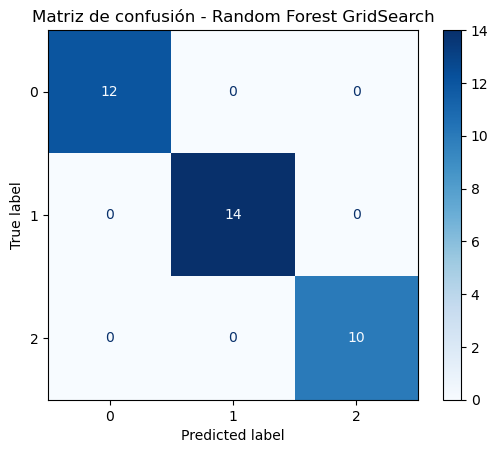

In [49]:
rf_grid_pred_train = modelo_rf_optimizado.predict(X_train_preparado)
rf_grid_pred_test = modelo_rf_optimizado.predict(X_test_preparado)
rf_grid_train_metrics = evaluar_modelo('Random Forest GridSearch', 'Training', y_train, rf_grid_pred_train)
rf_grid_test_metrics = evaluar_modelo('Random Forest GridSearch', 'Testing', y_test, rf_grid_pred_test)

In [50]:
profundidades = [arbol.get_depth() for arbol in modelo_rf_optimizado.estimators_]
hojas = [arbol.get_n_leaves() for arbol in modelo_rf_optimizado.estimators_]

print("Número de árboles:", modelo_rf_optimizado.n_estimators)
print("Profundidad promedio:", np.mean(profundidades))
print("Número promedio de hojas:", np.mean(hojas))

Número de árboles: 50
Profundidad promedio: 3.0
Número promedio de hojas: 6.3


El ajuste de hiperparámetros para random forest logró reducir la complejidad sin sacrificar el desempeño observado. El modelo optimizado utiliza solamente 50 árboles de profundidad máxima 3 y mantiene el accuracy del 100% en prueba.

## 7. Neural Networks

In [51]:
modelo_mlp = MLPClassifier( max_iter=500, random_state=42)
modelo_mlp.fit(X_train_preparado, y_train)

MLPClassifier(max_iter=500, random_state=42)

In [52]:
print("Número de iteraciones:", modelo_mlp.n_iter_)
print("Valor final de la pérdida:", modelo_mlp.loss_)

Número de iteraciones: 269
Valor final de la pérdida: 0.01253875065565211


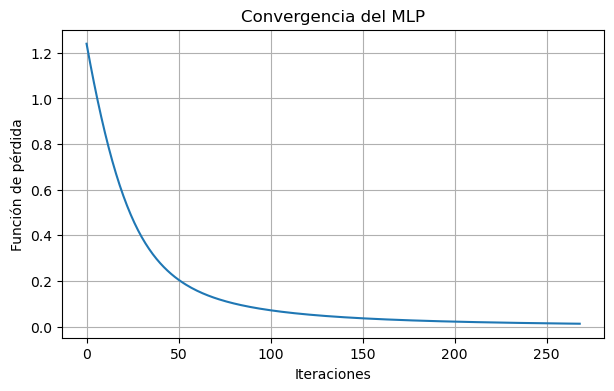

In [53]:
plt.figure(figsize=(7, 4))
plt.plot(modelo_mlp.loss_curve_)
plt.xlabel("Iteraciones")
plt.ylabel("Función de pérdida")
plt.title("Convergencia del MLP")
plt.grid(True)
plt.show()

Modelo: MLP
Accuracy : 1.0000

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        47
           1     1.0000    1.0000    1.0000        57
           2     1.0000    1.0000    1.0000        38

    accuracy                         1.0000       142
   macro avg     1.0000    1.0000    1.0000       142
weighted avg     1.0000    1.0000    1.0000       142



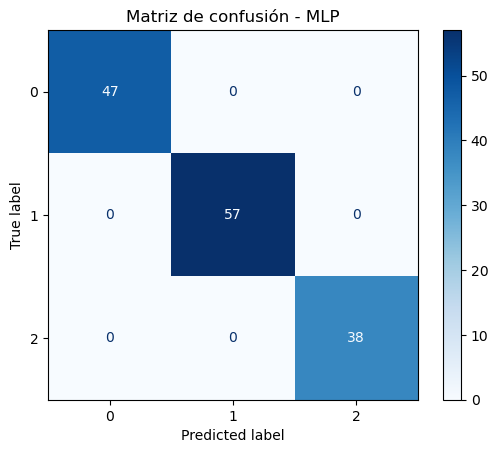

Modelo: MLP
Accuracy : 0.9722

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     0.9333    1.0000    0.9655        14
           2     1.0000    0.9000    0.9474        10

    accuracy                         0.9722        36
   macro avg     0.9778    0.9667    0.9710        36
weighted avg     0.9741    0.9722    0.9720        36



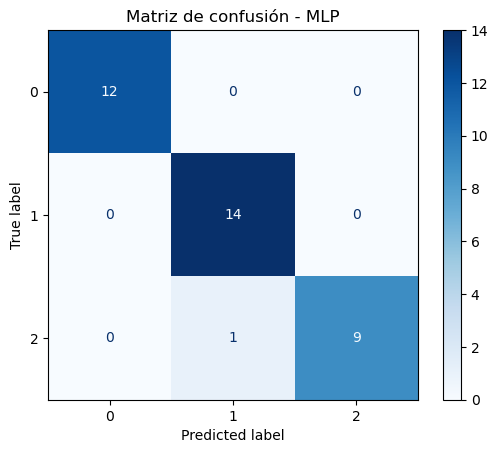

In [54]:
mlp_pred_train = modelo_mlp.predict(X_train_preparado)
mlp_pred_test = modelo_mlp.predict(X_test_preparado)

mlp_train_metrics = evaluar_modelo('MLP', 'Training', y_train, mlp_pred_train)
mlp_test_metrics = evaluar_modelo('MLP', 'Testing', y_test, mlp_pred_test)

El modelo MLP base, implementado con una capa oculta de 100 neuronas y función de activación ReLU, obtuvo un accuracy del 100% en entrenamiento y del 97.22% en prueba, clasificando correctamente 35 de las 36 muestras del conjunto de prueba. El F1-score macro alcanzó un valor de 0.9710, lo que evidencia un excelente desempeño en las tres clases. El proceso de entrenamiento finalizó después de 269 iteraciones, alcanzando un valor de pérdida de 0.0125. La curva de pérdida permite observar cómo disminuye el error durante el entrenamiento, lo que evidencia el proceso de aprendizaje de la red neuronal.

## 7.1 Ajuste de hiperparámetros para el modelo de redes neuronales

In [55]:
param_grid_mlp = {"hidden_layer_sizes": [(50,), (100,), (50, 25)], "activation": ["relu", "tanh"], 
                  "learning_rate_init": [0.001, 0.01]}

In [56]:
grid_mlp = GridSearchCV(modelo_mlp, param_grid_mlp, scoring="accuracy", cv=5, n_jobs=-1)
grid_mlp.fit(X_train_preparado, y_train)

GridSearchCV(cv=5, estimator=MLPClassifier(max_iter=500, random_state=42),
             n_jobs=-1,
             param_grid={'activation': ['relu', 'tanh'],
                         'hidden_layer_sizes': [(50,), (100,), (50, 25)],
                         'learning_rate_init': [0.001, 0.01]},
             scoring='accuracy')

In [57]:
resultados_grid_mlp = pd.DataFrame(grid_mlp.cv_results_)

resultados_grid_mlp = resultados_grid_mlp.rename(
    columns={"mean_test_score": "mean_val_score", "std_test_score": "std_val_score"})

display(resultados_grid_mlp[["param_hidden_layer_sizes", "param_activation",
                             "param_learning_rate_init", "mean_val_score", "std_val_score"]].round(4))

,param_hidden_layer_sizes,param_activation,param_learning_rate_init,mean_val_score,std_val_score
0,"(50,)",relu,0.001,0.9788,0.0285
1,"(50,)",relu,0.010,0.9931,0.0138
2,"(100,)",relu,0.001,0.9860,0.0172
3,"(100,)",relu,0.010,0.9860,0.0172
4,"(50, 25)",relu,0.001,0.9931,0.0138
5,"(50, 25)",relu,0.010,0.9931,0.0138
6,"(50,)",tanh,0.001,0.9860,0.0172
7,"(50,)",tanh,0.010,0.9860,0.0172
8,"(100,)",tanh,0.001,0.9791,0.0277
9,"(100,)",tanh,0.010,0.9791,0.0277


In [58]:
print("Mejores hiperparámetros:", grid_mlp.best_params_)
print("Mejor accuracy promedio en validación:", round(grid_mlp.best_score_, 4))

Mejores hiperparámetros: {'activation': 'relu', 'hidden_layer_sizes': (50,), 'learning_rate_init': 0.01}
Mejor accuracy promedio en validación: 0.9931


In [59]:
modelo_mlp_optimizado = grid_mlp.best_estimator_
print("Número de iteraciones:", modelo_mlp_optimizado.n_iter_)
print("Valor final de la pérdida:", modelo_mlp_optimizado.loss_)

Número de iteraciones: 68
Valor final de la pérdida: 0.0026648017705609506


Modelo: MLP GridSearch
Accuracy : 1.0000

Reporte de clasificación para: - Training
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        47
           1     1.0000    1.0000    1.0000        57
           2     1.0000    1.0000    1.0000        38

    accuracy                         1.0000       142
   macro avg     1.0000    1.0000    1.0000       142
weighted avg     1.0000    1.0000    1.0000       142



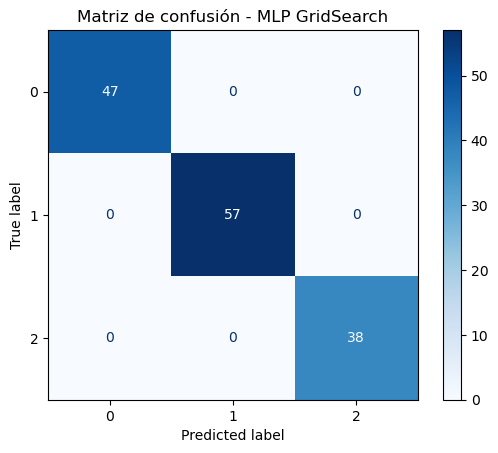

Modelo: MLP GridSearch
Accuracy : 0.9444

Reporte de clasificación para: - Testing
              precision    recall  f1-score   support

           0     0.9231    1.0000    0.9600        12
           1     0.9286    0.9286    0.9286        14
           2     1.0000    0.9000    0.9474        10

    accuracy                         0.9444        36
   macro avg     0.9505    0.9429    0.9453        36
weighted avg     0.9466    0.9444    0.9443        36



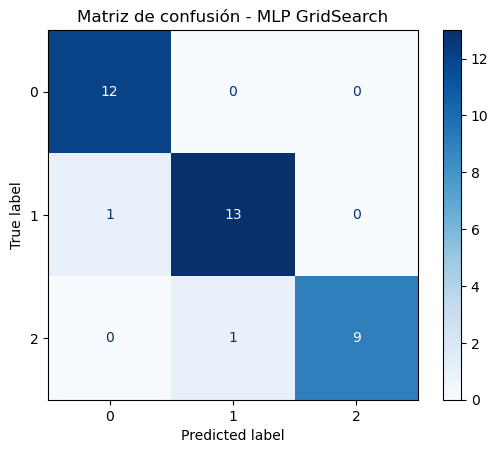

In [60]:
mlp_grid_pred_train = modelo_mlp_optimizado.predict(X_train_preparado)
mlp_grid_pred_test = modelo_mlp_optimizado.predict(X_test_preparado)

mlp_grid_train_metrics = evaluar_modelo('MLP GridSearch', 'Training', y_train, mlp_grid_pred_train)
mlp_grid_test_metrics = evaluar_modelo('MLP GridSearch', 'Testing', y_test, mlp_grid_pred_test)

In [61]:
comparacion_mlp = pd.DataFrame({"Modelo": ["MLP", "MLP GridSearch"],
                                "Accuracy entrenamiento": [accuracy_score(y_train, mlp_pred_train),
                                                           accuracy_score(y_train, mlp_grid_pred_train)],
                                "Accuracy prueba": [accuracy_score(y_test, mlp_pred_test), 
                                                    accuracy_score(y_test, mlp_grid_pred_test)]})
display(comparacion_mlp.round(4))

,Modelo,Accuracy entrenamiento,Accuracy prueba
0,MLP,1.0,0.9722
1,MLP GridSearch,1.0,0.9444


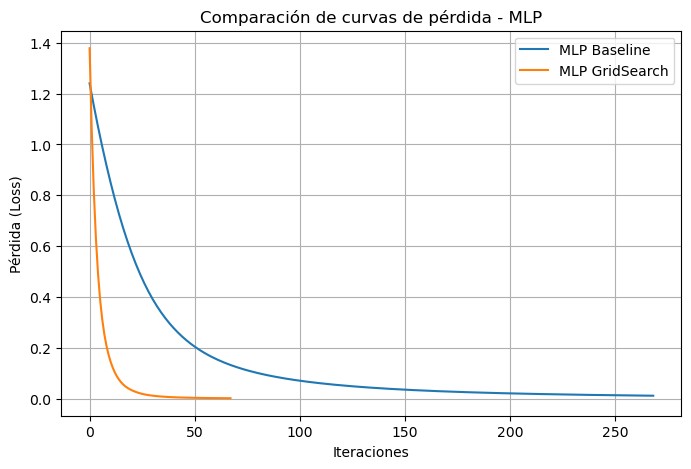

In [62]:
plt.figure(figsize=(8, 5))

plt.plot(modelo_mlp.loss_curve_, label="MLP Baseline")
plt.plot(modelo_mlp_optimizado.loss_curve_, label="MLP GridSearch")

plt.xlabel("Iteraciones")
plt.ylabel("Pérdida (Loss)")
plt.title("Comparación de curvas de pérdida - MLP")
plt.legend()
plt.grid(True)

plt.show()

In [63]:
print("MLP Baseline")
print("Iteraciones:", modelo_mlp.n_iter_)
print("Pérdida final:", round(modelo_mlp.loss_, 4))

print("\nMLP GridSearch")
print("Iteraciones:", modelo_mlp_optimizado.n_iter_)
print("Pérdida final:", round(modelo_mlp_optimizado.loss_, 4))

MLP Baseline
Iteraciones: 269
Pérdida final: 0.0125

MLP GridSearch
Iteraciones: 68
Pérdida final: 0.0027


La configuración seleccionada fue una red con una capa oculta de 50 neuronas, función de activación ReLU y tasa de aprendizaje de 0.01, alcanzando un accuracy promedio de 99.31% en validación cruzada, superior al 98.60% obtenido por la configuración base.

El modelo optimizado obtuvo un accuracy del 100% en entrenamiento y del 94.44% en prueba, clasificando correctamente 34 de las 36 muestras. Por tanto, aunque mejoró su desempeño promedio en validación cruzada, presentó una disminución del accuracy en prueba respecto al modelo base (97.22%).

En cuanto al proceso de entrenamiento, el modelo optimizado necesitó 68 iteraciones, frente a las 269 del modelo base, y alcanzó una pérdida final de 0.0027, inferior al valor de 0.0125 del modelo inicial. Esto evidencia una convergencia más rápida en términos de iteraciones y una menor pérdida sobre los datos de entrenamiento, aunque no se tradujo en una mejora de la clasificación en prueba.

El ajuste permitió obtener una red con menos neuronas y un mejor desempeño promedio en validación cruzada. Sin embargo, no se puede afirmar que haya mejorado su capacidad de generalización, especialmente considerando que el conjunto de prueba contiene únicamente 36 muestras.

## 8. Comparación final de los modelos

En esta sección se reúnen los resultados de todos los modelos entrenados en el notebook: las tres variantes de regresión SoftMax, los modelos SoftMax ajustados con GridSearchCV, el árbol de decisión, el bosque aleatorio y la red neuronal MLP, cada uno en su versión base y en su versión optimizada.

La comparación se realiza en dos partes. Primero se comparan las métricas obtenidas en los conjuntos de entrenamiento y prueba. Después se utilizan los resultados de la validación cruzada que GridSearchCV ya calculó, para estudiar qué tan robusto es el mejor modelo de cada experimento frente a cambios en los datos de entrenamiento.

### 8.1 Tabla comparativa en entrenamiento y prueba

Se reúnen las predicciones de cada modelo y se calculan accuracy, precision, recall y F1-score con promedio macro. La predicción del árbol de decisión base se recalcula, porque las variables tree_pred_train y tree_pred_test fueron reutilizadas para el árbol optimizado.

Para la regresión SoftMax con regularización se realizaron dos experimentos con GridSearchCV. En ambos la mejor penalización fue L2, con C = 0.01 en el primero y C = 0.5 en el segundo. Se incluye un solo modelo, el del segundo experimento, porque obtuvo el mayor accuracy promedio en validación cruzada (0.9931 frente a 0.9862). La selección se hace con la validación cruzada y no con el conjunto de prueba, que se reserva para la evaluación final.

Los modelos SoftMax L2 C=1 y SoftMax L1 C=0.1 corresponden a las secciones 6 y 7, donde el valor de C se fijó manualmente.

In [74]:
predicciones = {"SoftMax": (logistic_pred_train, logistic_pred_test),
                "SoftMax L2 C=1": (ridge_pred_train, ridge_pred_test),
                "SoftMax L1 C=0.1": (lasso_pred_train, lasso_pred_test),
                "SoftMax GridSearch": (grid_SoftMax_pred_train, grid_SoftMax_pred_test),
                "SoftMax L2 GridSearch": (grid_reg2_pred_train, grid_reg2_pred_test),
                "Decision Tree": (modelo_tree.predict(X_train_preparado), modelo_tree.predict(X_test_preparado)),
                "Decision Tree GridSearch": (tree_pred_train, tree_pred_test),
                "Random Forest": (rf_pred_train, rf_pred_test),
                "Random Forest GridSearch": (rf_grid_pred_train, rf_grid_pred_test),
                "MLP": (mlp_pred_train, mlp_pred_test),
                "MLP GridSearch": (mlp_grid_pred_train, mlp_grid_pred_test)}

In [65]:
filas = []
for nombre, (pred_train, pred_test) in predicciones.items():
    filas.append({"Modelo": nombre,
                  "Accuracy entrenamiento": accuracy_score(y_train, pred_train),
                  "Accuracy prueba": accuracy_score(y_test, pred_test),
                  "Precision prueba": precision_score(y_test, pred_test, average="macro"),
                  "Recall prueba": recall_score(y_test, pred_test, average="macro"),
                  "F1-score prueba": f1_score(y_test, pred_test, average="macro")})

comparacion_final = pd.DataFrame(filas)
comparacion_final["Diferencia train - test"] = (comparacion_final["Accuracy entrenamiento"]
                                                - comparacion_final["Accuracy prueba"])
display(comparacion_final.round(4))

,Modelo,Accuracy entrenamiento,Accuracy prueba,Precision prueba,Recall prueba,F1-score prueba,Diferencia train - test
0,SoftMax,1.0000,0.9722,0.9778,0.9667,0.9710,0.0278
1,SoftMax L2 C=1,1.0000,0.9722,0.9778,0.9667,0.9710,0.0278
2,SoftMax L1 C=0.1,0.9718,1.0000,1.0000,1.0000,1.0000,-0.0282
3,SoftMax GridSearch,1.0000,0.9722,0.9778,0.9667,0.9710,0.0278
4,SoftMax L2 GridSearch,1.0000,0.9722,0.9778,0.9667,0.9710,0.0278
5,Decision Tree,1.0000,0.9444,0.9583,0.9389,0.9457,0.0556
6,Decision Tree GridSearch,0.9859,1.0000,1.0000,1.0000,1.0000,-0.0141
7,Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
8,Random Forest GridSearch,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
9,MLP,1.0000,0.9722,0.9778,0.9667,0.9710,0.0278


### 18.2 Gráfico de barras: accuracy en entrenamiento y prueba

El gráfico permite comparar, para cada modelo, el accuracy obtenido en entrenamiento y en prueba. Una diferencia grande entre ambas barras es un indicio de sobreajuste.

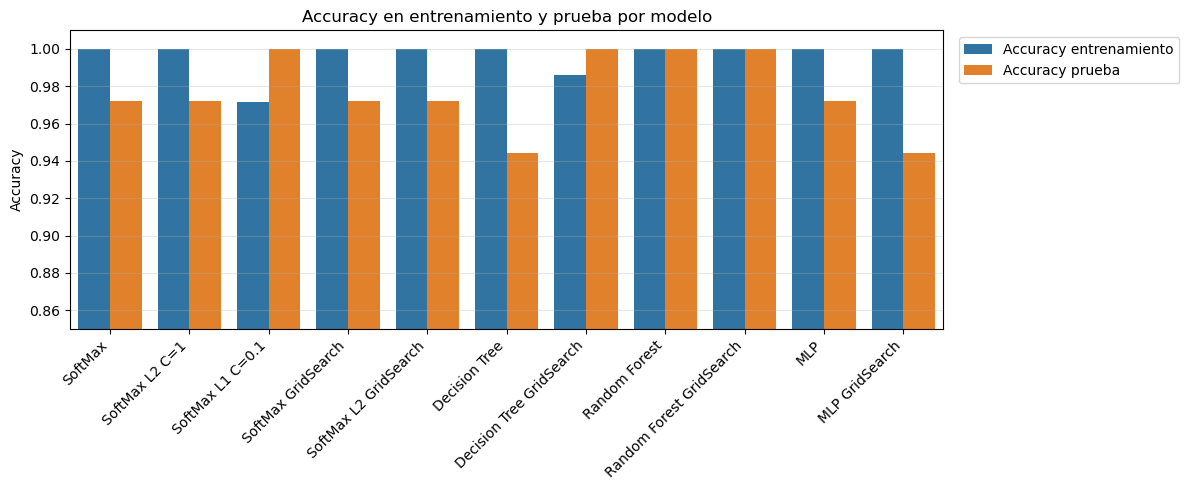

In [75]:
comparacion_barras = comparacion_final.melt(id_vars="Modelo",
                                            value_vars=["Accuracy entrenamiento", "Accuracy prueba"],
                                            var_name="Conjunto", value_name="Accuracy")

plt.figure(figsize=(12, 5))
sns.barplot(data=comparacion_barras, x="Modelo", y="Accuracy", hue="Conjunto")
plt.ylim(0.85, 1.01)
plt.title("Accuracy en entrenamiento y prueba por modelo")
plt.xlabel("")
plt.xticks(rotation=45, ha="right")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

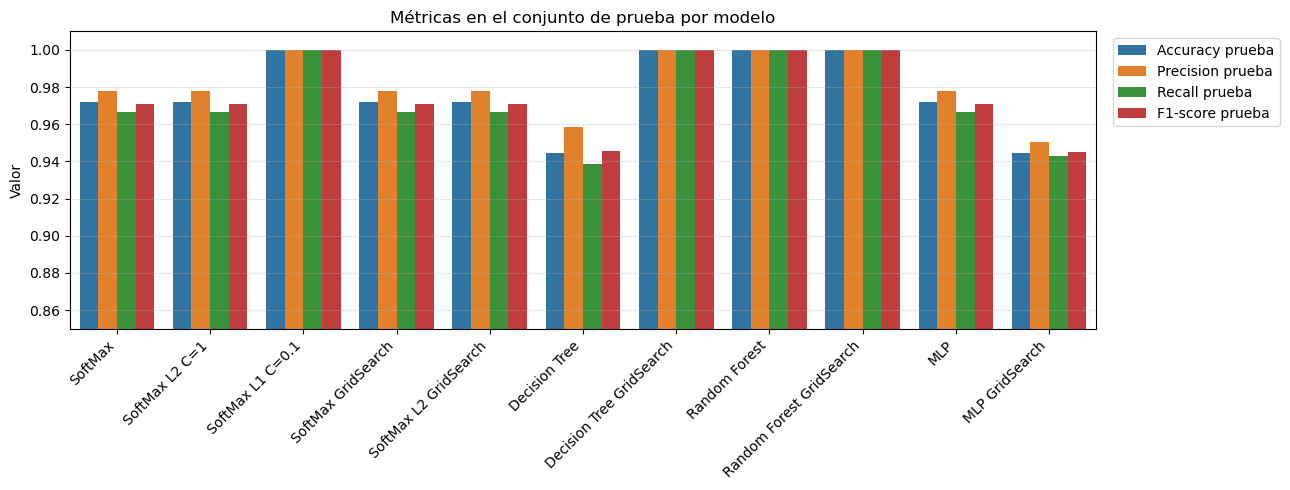

In [67]:
metricas_prueba = comparacion_final.melt(id_vars="Modelo",
                                         value_vars=["Accuracy prueba", "Precision prueba",
                                                     "Recall prueba", "F1-score prueba"],
                                         var_name="Métrica", value_name="Valor")

plt.figure(figsize=(13, 5))
sns.barplot(data=metricas_prueba, x="Modelo", y="Valor", hue="Métrica")
plt.ylim(0.85, 1.01)
plt.title("Métricas en el conjunto de prueba por modelo")
plt.xlabel("")
plt.xticks(rotation=45, ha="right")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 18.3 Resultados por partición de los mejores modelos de GridSearchCV

Durante la búsqueda, GridSearchCV evaluó cada combinación de hiperparámetros con validación cruzada de 5 particiones y guardó el accuracy de cada partición en cv_results_. El atributo best_index_ indica la fila de la mejor combinación. 

In [78]:
def scores_por_particion(grid, indice):
    return [grid.cv_results_[f"split{i}_test_score"][indice] for i in range(grid.n_splits_)]

mejores_grid = {"SoftMax GridSearch": grid_SoftMax,
                "SoftMax L2 GridSearch": grid_reg2,
                "Decision Tree GridSearch": grid_tree,
                "Random Forest GridSearch": grid_rf,
                "MLP GridSearch": grid_mlp}

filas = []
for nombre, grid in mejores_grid.items():
    for particion, score in enumerate(scores_por_particion(grid, grid.best_index_), start=1):
        filas.append({"Modelo": nombre, "Partición": particion, "Accuracy": score})

resultados_particiones = pd.DataFrame(filas)

In [79]:
tabla_particiones = resultados_particiones.pivot(index="Modelo", columns="Partición", values="Accuracy")
tabla_particiones = tabla_particiones.loc[list(mejores_grid.keys())]
#tabla_particiones.columns = [f"Partición {p}" for p in tabla_particiones.columns]

tabla_particiones["Media"] = tabla_particiones.mean(axis=1)
tabla_particiones["Desviación"] = tabla_particiones.iloc[:, :5].std(axis=1, ddof=0)
#tabla_particiones["Mínimo"] = tabla_particiones.iloc[:, :5].min(axis=1)
#tabla_particiones["Máximo"] = tabla_particiones.iloc[:, :5].max(axis=1)
tabla_particiones["Mejores hiperparámetros"] = [str(grid.best_params_) for grid in mejores_grid.values()]

display(tabla_particiones.round(4))

Partición,1,2,3,4,5,Media,Desviación,Mejores hiperparámetros
Modelo,,,,,,,,
SoftMax GridSearch,1.0000,0.9655,1.0000,0.9643,1.0,0.9860,0.0172,{'tol': 0.001}
SoftMax L2 GridSearch,1.0000,0.9655,1.0000,1.0000,1.0,0.9931,0.0138,"{'C': 0.5, 'penalty': 'l2'}"
Decision Tree GridSearch,0.8621,0.8966,0.9643,0.9286,1.0,0.9303,0.0486,"{'criterion': 'gini', 'max_depth': 3, 'min_sam..."
Random Forest GridSearch,1.0000,0.9310,1.0000,1.0000,1.0,0.9862,0.0276,"{'max_depth': 3, 'min_samples_leaf': 1, 'min_s..."
MLP GridSearch,1.0000,0.9655,1.0000,1.0000,1.0,0.9931,0.0138,"{'activation': 'relu', 'hidden_layer_sizes': (..."


Los resultados de la validación cruzada muestran diferencias tanto en el accuracy promedio como en la variabilidad del desempeño entre las cinco particiones, lo que permite comparar la estabilidad de los modelos ante diferentes subconjuntos de entrenamiento y validación. Los modelos SoftMax con regularización L2 y MLP obtuvieron los mejores resultados, con un accuracy promedio de 99.31% y una desviación estándar de 0.0138. Ambos alcanzaron un accuracy del 100% en cuatro de las cinco particiones y del 96.55% en la restante, mostrando un desempeño elevado y consistente. El modelo SoftMax sin regularización alcanzó un accuracy promedio de 98.60%, con una desviación estándar de 0.0172, mientras que Random Forest obtuvo un promedio de 98.62%, pero con mayor variabilidad (0.0276). Aunque sus desempeños promedio fueron prácticamente iguales, SoftMax presentó mayor estabilidad entre las particiones.

Por su parte, el árbol de decisión obtuvo el menor accuracy promedio (93.03%) y la mayor desviación estándar (0.0486). Su desempeño varió entre 86.21% y 100%, lo que indica una mayor sensibilidad a las muestras utilizadas en cada partición. En general, SoftMax con regularización L2 y MLP presentan los resultados más favorables en términos de accuracy promedio y estabilidad, mientras que el árbol de decisión muestra el comportamiento más variable.Sin embargo, las diferencias observadas deben interpretarse con precaución debido al tamaño reducido del conjunto de datos y al número limitado de particiones. 

### 11.4 Gráfico de robustez frente a las particiones

Con solo 5 valores por modelo, un diagrama de cajas no es apropiado, porque los cuartiles calculados con tan pocos datos son poco confiables. En su lugar se utiliza un diagrama de puntos: cada punto de color corresponde al accuracy de una partición, el rombo negro es la media y la línea vertical indica una desviación estándar. Los puntos de cada modelo se separan horizontalmente según la partición para que no se superpongan. Un modelo robusto muestra sus 5 puntos agrupados cerca de la media.

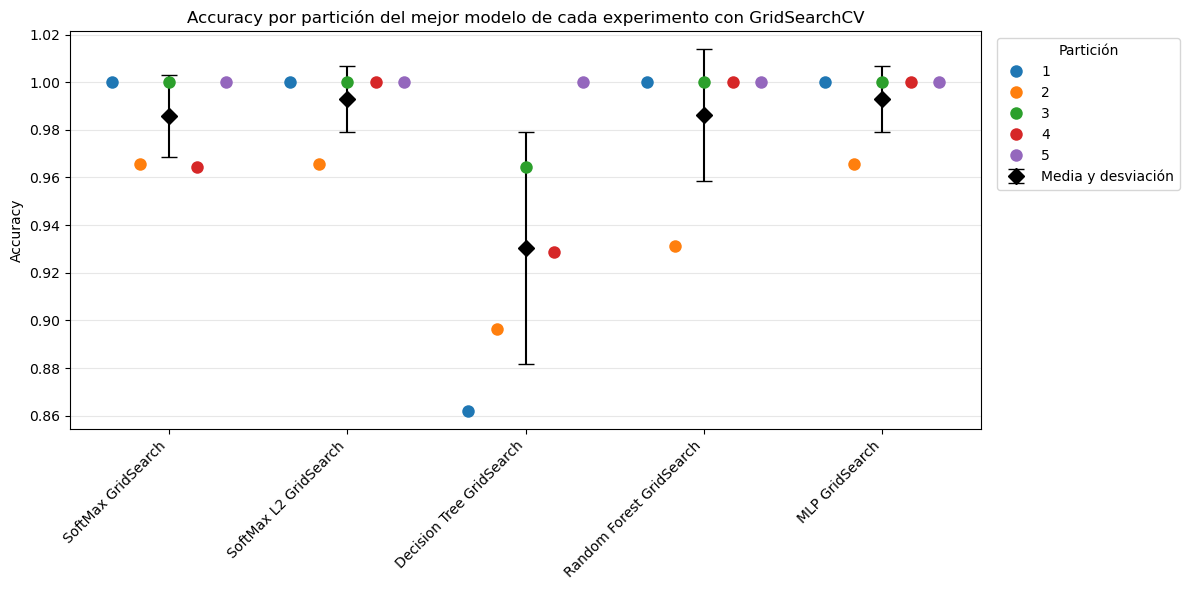

In [70]:
medias = tabla_particiones["Media"]
desviaciones = tabla_particiones["Desviación"]

plt.figure(figsize=(12, 6))
sns.stripplot(data=resultados_particiones, x="Modelo", y="Accuracy", hue="Partición",
              palette="tab10", size=9, dodge=True, jitter=False)
plt.errorbar(x=range(len(medias)), y=medias, yerr=desviaciones, fmt="D", color="black",
             markersize=8, capsize=6, label="Media y desviación")
plt.title("Accuracy por partición del mejor modelo de cada experimento con GridSearchCV")
plt.xlabel("")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Partición", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Los modelos SoftMax con regularización L2 y MLP presentan el comportamiento más estable, con valores de accuracy elevados en todas las particiones y variaciones relativamente pequeñas. Por su parte, SoftMax sin regularización y Random Forest también muestran un buen desempeño, aunque este último presenta fluctuaciones ligeramente mayores. El árbol de decisión exhibe la mayor variabilidad entre particiones, con un accuracy que oscila entre 86.21% y 100%. Esto sugiere una mayor sensibilidad del modelo a los subconjuntos de datos utilizados durante la validación. En general, el gráfico confirma que SoftMax con regularización L2 y MLP presentan los resultados más favorables en términos de rendimiento promedio y estabilidad, mientras que el árbol de decisión muestra un comportamiento menos consistente.

### 11.5 Mapa de calor del accuracy por partición

El mapa de calor muestra la misma información organizada como una tabla de modelos y particiones. Permite identificar si una partición resulta difícil para todos los modelos, lo que indicaría que la variación se debe a los datos de esa partición y no a un modelo en particular.

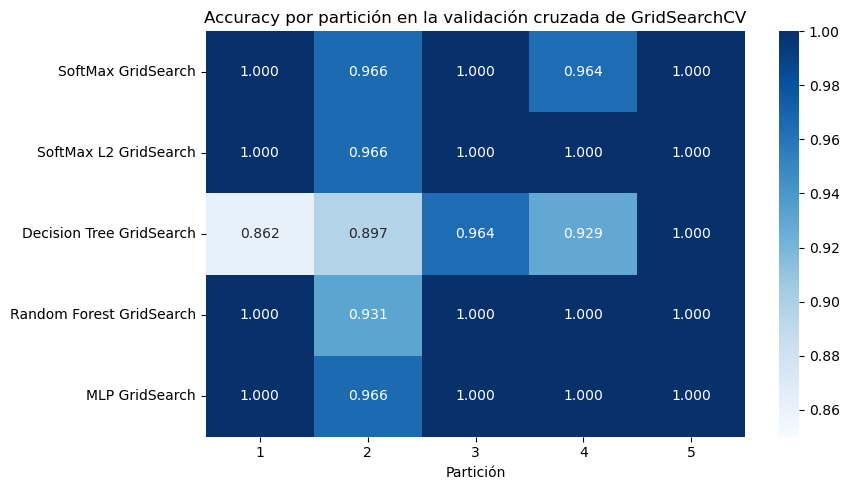

In [71]:
plt.figure(figsize=(9, 5))
sns.heatmap(tabla_particiones.iloc[:, :5], annot=True, fmt=".3f", cmap="Blues", vmin=0.85, vmax=1.0)
plt.title("Accuracy por partición en la validación cruzada de GridSearchCV")
plt.ylabel("")
plt.tight_layout()
plt.show()

Se observa que la quinta partición presenta un accuracy del 100% para todos los modelos, mientras que la segunda muestra una disminución del rendimiento en todos ellos. Esto sugiere que las muestras de la segunda partición podrían resultar más difíciles de clasificar, independientemente del algoritmo utilizado.

Los modelos SoftMax con regularización L2 y MLP presentan los resultados más uniformes, alcanzando un accuracy del 100% en cuatro de las cinco particiones. Por su parte, Random Forest presenta una disminución más pronunciada en la segunda partición (93.10%), mientras que el árbol de decisión exhibe el comportamiento más variable, especialmente en las particiones 1 y 2, con valores de 86.21% y 89.66%, respectivamente.

En general, el mapa de calor evidencia que las diferencias de rendimiento dependen tanto del modelo utilizado como de las muestras que conforman cada partición. Sin embargo, para determinar si algunas particiones presentan características que dificultan la clasificación, sería necesario analizar la distribución y las características de sus observaciones.

### 11.6 Modelo base frente a modelo optimizado con GridSearchCV

Las configuraciones por defecto del árbol de decisión, del bosque aleatorio y de la MLP forman parte de las rejillas evaluadas, al igual que la regresión SoftMax sin regularización con tol=1e-4. Por tanto, sus resultados de validación cruzada también se encuentran en cv_results_ y pueden compararse con los del mejor modelo de cada experimento. Para la regresión SoftMax se toma como modelo base la versión sin regularización y como modelo optimizado el modelo SoftMax L2 GridSearch, obtenido en el segundo experimento con GridSearchCV (C = 0.5).

In [72]:
familias = {"SoftMax": (grid_SoftMax, {"tol": 1e-4}, grid_reg2),
            "Decision Tree": (grid_tree, {"criterion": "gini", "max_depth": None,
                                          "min_samples_leaf": 1, "min_samples_split": 2}, grid_tree),
            "Random Forest": (grid_rf, {"max_depth": None, "min_samples_leaf": 1,
                                        "min_samples_split": 2, "n_estimators": 100}, grid_rf),
            "MLP": (grid_mlp, {"activation": "relu", "hidden_layer_sizes": (100,),
                               "learning_rate_init": 0.001}, grid_mlp)}

filas = []
for familia, (grid_base, parametros_base, grid_opt) in familias.items():
    indice_base = grid_base.cv_results_["params"].index(parametros_base)
    filas.append({"Familia": familia,
                  "Media base": grid_base.cv_results_["mean_test_score"][indice_base],
                  "Desviación base": grid_base.cv_results_["std_test_score"][indice_base],
                  "Media GridSearch": grid_opt.best_score_,
                  "Desviación GridSearch": grid_opt.cv_results_["std_test_score"][grid_opt.best_index_]})

comparacion_grid = pd.DataFrame(filas)
comparacion_grid["Mejora"] = comparacion_grid["Media GridSearch"] - comparacion_grid["Media base"]
display(comparacion_grid.round(4))

,Familia,Media base,Desviación base,Media GridSearch,Desviación GridSearch,Mejora
0,SoftMax,0.9860,0.0172,0.9931,0.0138,0.0071
1,Decision Tree,0.9163,0.0514,0.9303,0.0486,0.0140
2,Random Forest,0.9862,0.0276,0.9862,0.0276,0.0000
3,MLP,0.9860,0.0172,0.9931,0.0138,0.0071


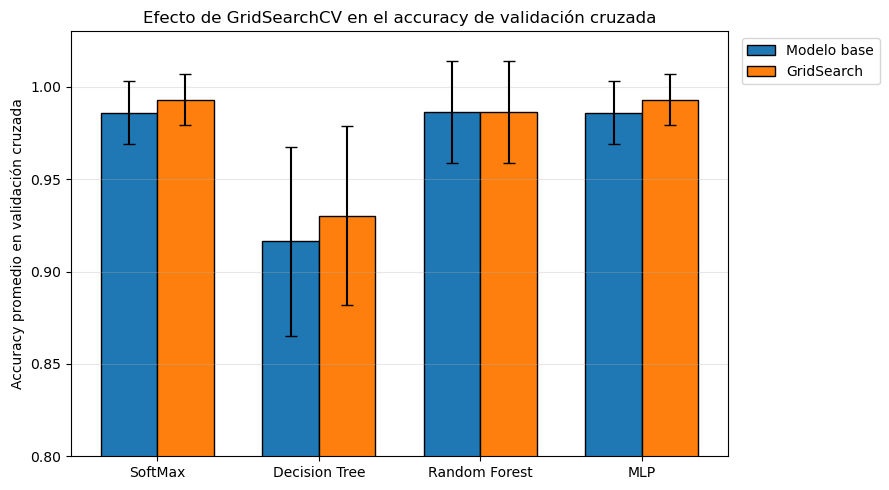

In [73]:
posiciones = np.arange(len(comparacion_grid))
ancho = 0.35

plt.figure(figsize=(9, 5))
plt.bar(posiciones - ancho / 2, comparacion_grid["Media base"], ancho, yerr=comparacion_grid["Desviación base"],
        capsize=4, label="Modelo base", edgecolor="black")
plt.bar(posiciones + ancho / 2, comparacion_grid["Media GridSearch"], ancho,
        yerr=comparacion_grid["Desviación GridSearch"], capsize=4, label="GridSearch", edgecolor="black")
plt.xticks(posiciones, comparacion_grid["Familia"])
plt.ylim(0.80, 1.03)
plt.ylabel("Accuracy promedio en validación cruzada")
plt.title("Efecto de GridSearchCV en el accuracy de validación cruzada")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Se observa que el árbol de decisión presentó la mayor mejora relativa, pasando de un accuracy promedio de 91.63% a 93.03%, aunque continúa siendo el modelo con menor rendimiento y mayor variabilidad. Por su parte, SoftMax y MLP mejoraron de 98.60% a 99.31%, acompañados de una ligera reducción en la desviación estándar, lo que sugiere un desempeño más estable entre las particiones.

En el caso de Random Forest, el ajuste no produjo cambios en el accuracy promedio (98.62%) ni en su desviación estándar (0.0276), lo que indica que las configuraciones base y optimizada presentaron el mismo desempeño durante la validación cruzada.

En general, el ajuste de hiperparámetros produjo mejoras pequeñas en el rendimiento promedio, especialmente en SoftMax y MLP, que alcanzaron los valores más altos. Sin embargo, las diferencias son reducidas y no permiten afirmar que los modelos optimizados tengan necesariamente una mayor capacidad de generalización.

## 12. Análisis general de los resultados de este Notebook

En el conjunto de prueba varios modelos alcanzan un accuracy de 1.000: SoftMax L1 C=0.1, el árbol de decisión optimizado y los dos bosques aleatorios. SoftMax L2 GridSearch, SoftMax sin regularización, SoftMax L2 C=1 y la MLP base obtienen 0.972, que corresponde a un solo error, mientras que el árbol base y la MLP optimizada obtienen 0.944, es decir, dos errores. Con solo 36 observaciones de prueba cada error equivale a 0.028 de accuracy, de modo que estas diferencias corresponden a una o dos muestras y no permiten elegir un modelo con seguridad.

Los resultados por partición de GridSearchCV muestran que SoftMax L2 GridSearch (C = 0.5) y la MLP optimizada son los modelos más robustos: ambos tienen un accuracy promedio de 0.993 y una desviación de 0.014, con 1.000 en cuatro de las cinco particiones. Cada partición de validación contiene 28 o 29 muestras, por lo que un valor de 0.966 corresponde a un solo error y un valor de 0.931 a dos errores. SoftMax sin regularización y el bosque aleatorio obtienen un promedio cercano a 0.986, es decir, la diferencia con los mejores modelos es de una o dos muestras mal clasificadas en una partición. En la práctica, estos modelos tienen un desempeño equivalente y estable frente a cambios en los datos de entrenamiento.

El mapa de calor muestra que la partición 2 es la más difícil para todos los modelos. Esto indica que la variación observada se debe principalmente a las muestras que contiene esa partición y no a una debilidad particular de un modelo.

El árbol de decisión optimizado es el modelo menos robusto: tiene el menor accuracy promedio (0.930), la mayor desviación (0.049) y valores que van desde 0.862 hasta 1.000. Un único árbol depende mucho de las muestras utilizadas para construirlo. El bosque aleatorio, que combina muchos árboles entrenados con diferentes muestras, reduce esta dependencia y alcanza resultados similares a los de los modelos lineales.

La mejora producida por GridSearchCV respecto a la configuración base es pequeña: 0.007 en SoftMax, al pasar del modelo sin regularización al modelo L2 con C = 0.5, 0.000 en Random Forest, cuya configuración por defecto obtiene el mismo resultado que la mejor combinación, y 0.007 en MLP. La mayor mejora se presenta en el árbol de decisión (0.014), porque limitar su profundidad reduce el sobreajuste del árbol base. Aun así, el árbol optimizado sigue siendo el modelo con mayor variación entre particiones.

Este ejemplo también ilustra cómo debe seleccionarse un modelo. El primer experimento con regularización (C = 0.01) obtuvo 1.000 en prueba, mientras que el segundo (C = 0.5) obtuvo 0.972. Sin embargo, se eligió el segundo porque tiene un mejor accuracy promedio en validación cruzada. Si se eligiera el modelo según su resultado en el conjunto de prueba, ese conjunto dejaría de ser una estimación independiente del desempeño, y la diferencia en este caso corresponde a una sola muestra.

Considerando desempeño, robustez y simplicidad, la regresión SoftMax con regularización L2 es una opción adecuada para este problema: alcanza el mismo desempeño y la misma estabilidad que la MLP en validación cruzada, se entrena rápidamente y sus coeficientes pueden interpretarse. Debe tenerse en cuenta que estas conclusiones se basan en solo 5 particiones y que las diferencias entre los mejores modelos equivalen a una o dos muestras.